In [ ]:
# تحميل أوزان BEATs من OneDrive إلى Drive مباشرة
import base64, os, urllib.request
from google.colab import drive
drive.mount('/content/drive')

url = 'https://1drv.ms/u/s!AqeByhGUtINrgcpke6_lRSZEKD5j2Q?e=A3FpOf'
enc = base64.b64encode(url.encode()).decode().rstrip('=').replace('/', '_').replace('+', '-')
direct = f'https://api.onedrive.com/v1.0/shares/u!{enc}/root/content'

os.makedirs('/content/drive/MyDrive/models', exist_ok=True)
out = '/content/drive/MyDrive/models/BEATs_iter3_plus_AS2M.pt'
urllib.request.urlretrieve(direct, out)
print('الحجم:', round(os.path.getsize(out)/1e6), 'MB')

Mounted at /content/drive


HTTPError: HTTP Error 401: Unauthorized

In [ ]:
# تحميل أوزان BEATs من HuggingFace إلى Drive والتأكد منها
import os, shutil, torch
from huggingface_hub import list_repo_files, hf_hub_download
from google.colab import drive
drive.mount('/content/drive')

FN  = 'BEATs_iter3_plus_AS2M.pt'
OUT = '/content/drive/MyDrive/models/' + FN
os.makedirs(os.path.dirname(OUT), exist_ok=True)

for repo in ['lpepino/beats_ckpts', 'alibabasglab/beats']:
    try:
        files = [f for f in list_repo_files(repo) if f.endswith(FN)]
        print(repo, '→', files)
        if files:
            p = hf_hub_download(repo, files[0]); shutil.copy(p, OUT); break
    except Exception as e: print(repo, '✗', type(e).__name__)

ck = torch.load(OUT, map_location='cpu', weights_only=False)
print('الحجم:', round(os.path.getsize(OUT)/1e6), 'MB | المفاتيح:', list(ck.keys()))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
lpepino/beats_ckpts → ['BEATs_iter3_plus_AS2M.pt']


BEATs_iter3_plus_AS2M.pt: reconstructing file:   0%|          |  0.00B /  361MB            

BEATs_iter3_plus_AS2M.pt: downloading bytes:           |  0.00B            

الحجم: 361 MB | المفاتيح: ['cfg', 'model']


In [ ]:
# الفكرة: BEATs — تحميل الكود الرسمي والتحقق من الـ checkpoint
# الهدف: تجهيز الـ backbone والتأكد من شكل المخرجات (زمن × 8 تردد) قبل بناء كاش الـ waveform
# المصدر: Chen et al., ICML 2023 — github.com/microsoft/unilm/tree/master/beats
import os, sys, urllib.request, torch
from google.colab import drive
drive.mount('/content/drive')

ROOT = '/content/drive/MyDrive'
CODE = f'{ROOT}/models/beats_code'
CKPT = f'{ROOT}/models/BEATs_iter3_plus_AS2M.pt'
os.makedirs(CODE, exist_ok=True)

# تنزيل ملفات الكود مرة واحدة وحفظها على Drive
RAW = 'https://raw.githubusercontent.com/microsoft/unilm/master/beats/'
for f in ['BEATs.py', 'backbone.py', 'modules.py']:
    p = f'{CODE}/{f}'
    if not os.path.exists(p) or os.path.getsize(p) < 1000:
        urllib.request.urlretrieve(RAW + f, p)
    print(f'{f}: {os.path.getsize(p):,} bytes')
sys.path.insert(0, CODE)
from BEATs import BEATs, BEATsConfig

# تحميل الـ checkpoint ومطابقة الأوزان مع المعمارية الرسمية
assert os.path.exists(CKPT), 'checkpoint not found'
print(f'checkpoint: {os.path.getsize(CKPT)/1e6:.1f} MB')
ck = torch.load(CKPT, map_location='cpu', weights_only=False)
cfg = BEATsConfig(ck['cfg'])
model = BEATs(cfg)
res = model.load_state_dict(ck['model'], strict=False)
print('missing keys   :', list(res.missing_keys))
print('unexpected keys:', list(res.unexpected_keys))
print('finetuned_model:', cfg.finetuned_model, '| predictor:', model.predictor)
print('embed_dim:', cfg.encoder_embed_dim, '| layers:', cfg.encoder_layers,
      '| patch:', cfg.input_patch_size,
      '| params: %.1fM' % (sum(p.numel() for p in model.parameters())/1e6))

# اختبار forward على 15 ثانية بتردد 16 kHz
dev = 'cuda' if torch.cuda.is_available() else 'cpu'
model = model.to(dev).eval()
x = torch.randn(2, 16000*15, device=dev) * 0.1
with torch.no_grad():
    feats = model.extract_features(x, padding_mask=None)[0]
print('device:', dev, '| output:', tuple(feats.shape))
assert feats.shape[1] % 8 == 0, 'token count is not a multiple of 8'
print('time steps =', feats.shape[1]//8, '× 8 freq')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
BEATs.py: 6,798 bytes
backbone.py: 30,743 bytes
modules.py: 7,387 bytes
checkpoint: 361.5 MB


/usr/local/lib/python3.13/dist-packages/torch/nn/utils/weight_norm.py:144: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)


missing keys   : []
unexpected keys: []
finetuned_model: False | predictor: None
embed_dim: 768 | layers: 12 | patch: 16 | params: 90.3M
device: cuda | output: (2, 744, 768)
time steps = 93 × 8 freq


In [ ]:
# الفكرة: تنزيل HF_Lung_V1 مباشرة من المصدر الرسمي إلى قرص Colab المحلي (بدل القراءة البطيئة من Drive)
# الهدف: الحصول على ملفات wav محلياً خلال دقائق، ثم بناء كاش الـ waveform منها
# المصدر: Hsu et al., 2021 — gitlab.com/techsupportHF/HF_Lung_V1
import os, time, collections
REPO = '/content/HF_Lung_V1'
t = time.time()
if not os.path.exists(REPO):
    !git clone --depth 1 https://gitlab.com/techsupportHF/HF_Lung_V1.git {REPO}
print('clone: %.1f min' % ((time.time() - t)/60))
!du -sh {REPO}
!ls -la {REPO}

# عدّ الملفات حسب المجلد والامتداد
cnt = collections.Counter()
for d, _, fs in os.walk(REPO):
    if os.sep + '.git' in d: continue
    top = os.path.relpath(d, REPO).split(os.sep)[0]
    for f in fs: cnt[(top, os.path.splitext(f)[1].lower())] += 1
for k, v in sorted(cnt.items()): print(k, v)

Cloning into '/content/HF_Lung_V1'...
remote: Enumerating objects: 18, done.
remote: Counting objects: 100% (18/18), done.
remote: Compressing objects: 100% (6/6), done.
remote: Total 18 (delta 0), reused 17 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (18/18), 883.39 MiB | 42.00 MiB/s, done.
Updating files: 100% (16/16), done.
clone: 0.5 min
2.0G	/content/HF_Lung_V1
total 1147308
drwxr-xr-x 3 root root     4096 Oct 10 13:42 .
drwxr-xr-x 1 root root     4096 Oct 10 13:42 ..
-rw-r--r-- 1 root root      391 Oct 10 13:42 Disclaimer
drwxr-xr-x 8 root root     4096 Oct 10 13:42 .git
-rw-r--r-- 1 root root    18650 Oct 10 13:42 LICENSE
-rw-r--r-- 1 root root     5018 Oct 10 13:42 README.md
-rw-r--r-- 1 root root 94371840 Oct 10 13:42 test.7z.001
-rw-r--r-- 1 root root 94371840 Oct 10 13:42 test.7z.002
-rw-r--r-- 1 root root 46498282 Oct 10 13:42 test.7z.003
-rw-r--r-- 1 root root 94371840 Oct 10 13:42 train.7z.001
-rw-r--r-- 1 root root 94371840 Oct 10 13:42 train.7z.002
-rw-r--

In [ ]:
# الفكرة: فك أرشيف HF_Lung_V1 محلياً وبناء كاش Waveform خام (int16، 4 kHz)
# الهدف: تجهيز مدخل BEATs بنفس ترتيب train_names/test_names، مع فحص المحاذاة مقابل كاش الـ log-mel
# المصدر: Hsu et al., 2021 (HF_Lung_V1، gitlab.com/techsupportHF/HF_Lung_V1) — Chen et al., ICML 2023 (BEATs)
import os, shutil, subprocess, numpy as np, soundfile as sf, librosa
from concurrent.futures import ThreadPoolExecutor
from tqdm.auto import tqdm

REPO, RAWD, OUT = '/content/HF_Lung_V1', '/content/hf_raw', '/content/wav_cache'
CACHE = '/content/drive/MyDrive/crnn_cache'
SR, L, MU, SD = 4000, 60000, -8.5267, 2.4603
os.makedirs(OUT, exist_ok=True)

# تنزيل وفك الأرشيف (يُتخطى إن كان موجوداً)
if not os.path.exists(REPO):
    subprocess.run(['git', 'clone', '-q', '--depth', '1',
                    'https://gitlab.com/techsupportHF/HF_Lung_V1.git', REPO], check=True)
if not shutil.which('7z'):
    subprocess.run('apt-get -qq install -y p7zip-full', shell=True, check=True)
for s in ['train', 'test']:
    if not os.path.exists(f'{RAWD}/{s}/.done'):
        subprocess.run(['7z', 'x', '-y', '-bso0', '-bsp0', f'{REPO}/{s}.7z.001', f'-o{RAWD}/{s}'], check=True)
        open(f'{RAWD}/{s}/.done', 'w').close()

def stem(x): return os.path.splitext(os.path.basename(str(x)))[0]

def read(path):
    y, sr = sf.read(path, dtype='int16', always_2d=True)
    y = y[:, 0]; n = len(y)
    out = np.zeros(L, np.int16); out[:min(n, L)] = y[:L]
    return out, sr, n

def zmel(w):
    m = librosa.feature.melspectrogram(y=w.astype(np.float32)/32768, sr=SR, n_fft=512,
                                       hop_length=64, n_mels=128, fmin=50, fmax=2000)
    return ((np.log(m + 1e-5) - MU)/SD)[:, :938].ravel()

for s in ['train', 'test']:
    names = np.load(f'{CACHE}/{s}_names.npy', allow_pickle=True)
    idx = {stem(f): os.path.join(d, f) for d, _, fs in os.walk(f'{RAWD}/{s}')
           for f in fs if f.lower().endswith('.wav')}
    miss = [n for n in names if stem(n) not in idx]
    assert not miss, f'{s}: {len(miss)} missing, e.g. {miss[:3]} | have e.g. {list(idx)[:3]}'
    dst = f'{OUT}/{s}_wav.npy'

    # بناء الكاش (يُتخطى إن كان موجوداً)
    if not os.path.exists(dst):
        W = np.lib.format.open_memmap(dst + '.tmp', mode='w+', dtype=np.int16, shape=(len(names), L))
        srs, lens = set(), []
        with ThreadPoolExecutor(8) as ex:
            paths = [idx[stem(n)] for n in names]
            for i, (y, sr, n) in enumerate(tqdm(ex.map(read, paths), total=len(paths), desc=s)):
                W[i] = y; srs.add(sr); lens.append(n)
        W.flush(); del W; os.replace(dst + '.tmp', dst)
        print(f'{s}: wav files={len(idx)} | sr={srs} | length min/max={min(lens)}/{max(lens)}')

    # فحص المحاذاة: ارتباط mel المحسوب من الموجة مع الكاش (نفس الملف مقابل ملف آخر)
    W = np.load(dst, mmap_mode='r'); X = np.load(f'{CACHE}/{s}_X.npy', mmap_mode='r')
    ii = np.random.default_rng(42).choice(len(names), 4, replace=False)
    same  = [np.corrcoef(zmel(W[i]), X[i].astype(np.float32).ravel())[0, 1] for i in ii]
    other = [np.corrcoef(zmel(W[i]), X[(i + 7) % len(names)].astype(np.float32).ravel())[0, 1] for i in ii]
    print(f'{s}: shape={W.shape} | corr same={np.round(same, 3)} | corr other={np.round(other, 3)}')

print('size: %.2f GB' % (sum(os.path.getsize(f'{OUT}/{f}') for f in os.listdir(OUT))/1e9))

train:   0%|          | 0/7809 [00:00<?, ?it/s]

train: wav files=7809 | sr={4000} | length min/max=60000/60000
train: shape=(7809, 60000) | corr same=[1. 1. 1. 1.] | corr other=[0.64  0.344 0.479 0.718]


test:   0%|          | 0/1956 [00:00<?, ?it/s]

test: wav files=1956 | sr={4000} | length min/max=60000/60000
test: shape=(1956, 60000) | corr same=[1. 1. 1. 1.] | corr other=[0.448 0.394 0.75  0.714]
size: 1.17 GB


In [ ]:
# الفكرة: BEATs + Frame Head (7 مخرجات) — بناء البيانات والنموذج
# الهدف: نفس رأس AST (mean على التردد → LayerNorm → Dropout → Linear → 938 إطاراً) فوق backbone أقوى، على fold 0
# المصدر: Chen et al., ICML 2023 (BEATs) — Park et al., 2019 (SpecAugment) — Hsu et al., 2021 (HF_Lung_V1)
import os, sys, time, numpy as np, torch, torch.nn as nn, torch.nn.functional as F, torchaudio
from torch.utils.data import DataLoader, TensorDataset

ROOT = '/content/drive/MyDrive'; CACHE = f'{ROOT}/crnn_cache'; WAV = '/content/wav_cache'
sys.path.insert(0, f'{ROOT}/models/beats_code')
from BEATs import BEATs, BEATsConfig
torch.manual_seed(42); np.random.seed(42)
torch.backends.cuda.matmul.allow_tf32 = True; torch.backends.cudnn.allow_tf32 = True
dev, VAL_FOLD, BS, T_OUT = 'cuda', 0, 16, 938

# البيانات: موجات int16 في الذاكرة + labels الإطارات (6 أصناف)
W    = torch.from_numpy(np.load(f'{WAV}/train_wav.npy'))
Yf   = torch.from_numpy(np.load(f'{CACHE}/train_Yf.npy'))
fold = np.load(f'{CACHE}/train_fold.npy')
assert W.shape == (7809, 60000) and Yf.shape == (7809, 938, 6)
tr, va = np.where(fold != VAL_FOLD)[0], np.where(fold == VAL_FOLD)[0]
dl_tr = DataLoader(TensorDataset(W[tr], Yf[tr]), batch_size=BS, shuffle=True, drop_last=True, pin_memory=True)
dl_va = DataLoader(TensorDataset(W[va], Yf[va]), batch_size=64, shuffle=False, pin_memory=True)

def spec_augment(fb, n_f=2, f_max=16, n_t=1, t_max=64, f_content=70):
    # قناعا تردد (≤16 bin ضمن النطاق الفعلي <2 kHz) وقناع زمن (≤64 إطاراً = 640 ms كما في AST)
    fb = fb.clone(); B, T, _ = fb.shape
    for i in range(B):
        for _ in range(n_f):
            w = np.random.randint(0, f_max + 1); f0 = np.random.randint(0, f_content - w + 1)
            fb[i, :, f0:f0 + w] = 0
        for _ in range(n_t):
            w = np.random.randint(0, t_max + 1); t0 = np.random.randint(0, T - w + 1)
            fb[i, t0:t0 + w, :] = 0
    return fb

class BEATsFrame(nn.Module):
    def __init__(self, beats, n_out=7, t_out=T_OUT, p=0.1):
        super().__init__()
        self.beats, self.t_out = beats, t_out
        self.resample = torchaudio.transforms.Resample(4000, 16000)
        d = beats.cfg.encoder_embed_dim
        self.norm, self.drop, self.fc = nn.LayerNorm(d), nn.Dropout(p), nn.Linear(d, n_out)

    @torch.no_grad()
    def fbank(self, wav):                                   # wav: (B, 60000) في المجال [-1, 1]
        with torch.autocast('cuda', enabled=False):
            return self.beats.preprocess(self.resample(wav.float()))   # (B, 1498, 128)

    def forward(self, wav):
        fb = self.fbank(wav)
        if self.training: fb = spec_augment(fb)
        b = self.beats
        x = b.patch_embedding(fb.unsqueeze(1))              # (B, 512, 93, 8)
        Tt, Ff = x.shape[2], x.shape[3]
        x = b.layer_norm(x.flatten(2).transpose(1, 2))      # (B, 744, 512)
        if b.post_extract_proj is not None: x = b.post_extract_proj(x)
        x, _ = b.encoder(b.dropout_input(x), padding_mask=None)
        x = x.reshape(x.shape[0], Tt, Ff, -1).mean(2)       # mean على التردد → (B, 93, 768)
        z = self.fc(self.drop(self.norm(x))).float()        # (B, 93, 7)
        return F.interpolate(z.transpose(1, 2), size=self.t_out, mode='linear',
                             align_corners=False).transpose(1, 2)      # (B, 938, 7)

def build_model():
    ck = torch.load(f'{ROOT}/models/BEATs_iter3_plus_AS2M.pt', map_location='cpu', weights_only=False)
    beats = BEATs(BEATsConfig(ck['cfg'])); beats.load_state_dict(ck['model'])
    return BEATsFrame(beats).to(dev)

model = build_model()

# فحص: شكل المخرجات وزمن الخطوة (forward + backward بدون تحديث أوزان)
model.train()
for i, (w, y) in zip(range(7), dl_tr):
    if i == 2: torch.cuda.synchronize(); t0 = time.time()
    with torch.autocast('cuda', dtype=torch.bfloat16):
        z = model(w.to(dev).float()/32768)
    z.mean().backward(); model.zero_grad(set_to_none=True)
torch.cuda.synchronize(); dt = (time.time() - t0)/5
print(f'train={len(tr)} | val={len(va)} | steps/epoch={len(dl_tr)}')
print(f'output={tuple(z.shape)} | finite={bool(torch.isfinite(z).all())} | params={sum(p.numel() for p in model.parameters())/1e6:.1f}M')
print(f'{dt:.3f} s/step → ~{dt*len(dl_tr)/60:.1f} min/epoch (train) | GPU mem={torch.cuda.max_memory_allocated()/1e9:.1f} GB')

/usr/local/lib/python3.13/dist-packages/torch/nn/utils/weight_norm.py:144: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)


train=5758 | val=2051 | steps/epoch=359
output=(16, 938, 7) | finite=True | params=90.3M
0.263 s/step → ~1.6 min/epoch (train) | GPU mem=16.5 GB


In [ ]:
# الفكرة: تدريب Pilot لـ BEATs على fold 0 (نفس loss ونفس جدول تدريب AST)
# الهدف: مقارنة selection = 0.5 × (Macro-AUC للأصناف الستة + Alert AUC) مع مرجع AST (0.8745)؛ القبول ≥ 0.880
# المصدر: Chen et al., ICML 2023 (BEATs) — Loshchilov & Hutter, 2019 (AdamW) و 2017 (cosine) — Hsu et al., 2021 (HF_Lung_V1)
import json, math, pandas as pd
from sklearn.metrics import roc_auc_score

RUN = f'{ROOT}/beats_pilot'; os.makedirs(RUN, exist_ok=True)
LAST, BEST, HIST = f'{RUN}/fold0_last.pt', f'{RUN}/fold0_best.pt', f'{RUN}/fold0_hist.json'
MAX_EP, SCHED_EP, PATIENCE = 8, 25, 5
CLASSES = ['Inhalation', 'Exhalation', 'Crackle', 'Wheeze', 'Stridor', 'Rhonchi']

def to7(y):                                   # 6 أصناف → 7 (إضافة Abnormal = أي من Crackle/Wheeze/Stridor/Rhonchi)
    y = y.float(); return torch.cat([y, y[..., 2:].amax(-1, keepdim=True)], -1)

def clip_prob(z):                             # احتمال المقطع = max عبر الزمن لـ avg-pool (k=9) على sigmoid الإطارات
    return F.avg_pool1d(torch.sigmoid(z).transpose(1, 2), 9, stride=1, padding=4).amax(-1)

# pos_weight من بيانات التدريب فقط، مقصوص بين 1 و 10 (للإطار وللمقطع)
Y7tr = to7(Yf[tr]); rf, rc = Y7tr.mean((0, 1)), Y7tr.amax(1).mean(0)
PW_F, PW_C = ((1 - rf)/rf).clamp(1, 10).to(dev), ((1 - rc)/rc).clamp(1, 10).to(dev)
del Y7tr

def loss_fn(z, y7):                           # frame BCE + clip BCE
    lf = F.binary_cross_entropy_with_logits(z, y7, pos_weight=PW_F)
    p, yc = clip_prob(z).clamp(1e-6, 1 - 1e-6), y7.amax(1)
    return lf - (PW_C*yc*torch.log(p) + (1 - yc)*torch.log1p(-p)).mean()

@torch.no_grad()
def evaluate(model):
    model.eval(); P, Y, L = [], [], 0.0
    for w, y in dl_va:
        y7 = to7(y.to(dev))
        with torch.autocast('cuda', dtype=torch.bfloat16):
            z = model(w.to(dev).float()/32768)
        L += loss_fn(z, y7).item()*len(w)
        P.append(clip_prob(z).cpu()); Y.append(y7.amax(1).cpu())
    P, Y = torch.cat(P).numpy(), torch.cat(Y).numpy()
    auc = [float(roc_auc_score(Y[:, c], P[:, c])) if 0 < Y[:, c].sum() < len(Y) else float('nan') for c in range(7)]
    return L/len(Y), auc, P

def save_drive(obj, path):
    try: torch.save(obj, path + '.tmp'); os.replace(path + '.tmp', path)
    except Exception as e: print('⚠️ save failed:', e)

done = os.path.exists(HIST) and json.load(open(HIST)).get('done', False)
if done:
    hist = json.load(open(HIST))['hist']
else:
    torch.manual_seed(42); np.random.seed(42)
    model = build_model(); spe = len(dl_tr)
    opt = torch.optim.AdamW([{'params': model.beats.parameters(), 'lr': 2e-5},
                             {'params': [*model.norm.parameters(), *model.fc.parameters()], 'lr': 1e-3}],
                            weight_decay=1e-4)
    # warmup لـ epoch واحد ثم cosine محسوب على 25 epoch (كما في AST)، ونتوقف عند 8
    lam = lambda s: (s + 1)/spe if s < spe else 0.5*(1 + math.cos(math.pi*(s - spe)/((SCHED_EP - 1)*spe)))
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lam)
    hist, best, bad, ep0 = [], -1.0, 0, 0

    # استئناف تلقائي بعد انقطاع الجلسة
    if os.path.exists(LAST):
        ck = torch.load(LAST, map_location=dev, weights_only=False)
        model.load_state_dict(ck['model']); opt.load_state_dict(ck['opt']); sched.load_state_dict(ck['sched'])
        hist, best, bad, ep0 = ck['hist'], ck['best'], ck['bad'], ck['epoch'] + 1
        print(f'resumed from epoch {ep0}')

    for ep in range(ep0, MAX_EP):
        if bad >= PATIENCE: break
        model.train(); t0, tl = time.time(), 0.0
        for w, y in dl_tr:
            y7 = to7(y.to(dev, non_blocking=True))
            with torch.autocast('cuda', dtype=torch.bfloat16):
                z = model(w.to(dev, non_blocking=True).float()/32768)
            loss = loss_fn(z, y7)
            opt.zero_grad(set_to_none=True); loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step(); sched.step()
            tl += loss.item()
        vl, auc, P = evaluate(model)
        m6, al = float(np.nanmean(auc[:6])), auc[6]; sel = 0.5*(m6 + al)
        hist.append(dict(epoch=ep, train_loss=tl/spe, val_loss=vl, **dict(zip(CLASSES, auc[:6])),
                         macro_auc6=m6, alert_auc=al, selection=sel, minutes=(time.time() - t0)/60))
        star = ''
        if sel > best:
            best, bad, star = sel, 0, ' ★'
            save_drive({k: v.half() if v.is_floating_point() else v for k, v in model.state_dict().items()}, BEST)
            np.save(f'{RUN}/fold0_best_val_prob.npy', P)
        else: bad += 1
        # حفظ على Drive بعد كل epoch
        save_drive(dict(model=model.state_dict(), opt=opt.state_dict(), sched=sched.state_dict(),
                        hist=hist, best=best, bad=bad, epoch=ep), LAST)
        json.dump(dict(hist=hist, done=False), open(HIST, 'w'))
        print(f'ep {ep} | train {tl/spe:.4f} | val {vl:.4f} | 6-class AUC {m6:.4f} | Alert AUC {al:.4f} '
              f'| selection {sel:.4f}{star} | {hist[-1]["minutes"]:.1f} min')

    json.dump(dict(hist=hist, done=True), open(HIST, 'w'))
    if os.path.exists(LAST): os.remove(LAST)          # تحرير مساحة Drive بعد اكتمال الـ Pilot

# جدول النتائج والحكم
df = pd.DataFrame(hist); b = df.loc[df.selection.idxmax()]
display(df[['epoch', 'train_loss', 'val_loss', 'macro_auc6', 'alert_auc', 'selection']].round(4))
print(f'BEATs best: epoch {int(b.epoch)} | 6-class {b.macro_auc6:.4f} | Alert {b.alert_auc:.4f} | selection {b.selection:.4f}')
print('AST reference: 6-class 0.8567 | Alert 0.8923 | selection 0.8745')
print('→ PASS (≥ 0.880): continue to 5-fold' if b.selection >= 0.880 else '→ below 0.880')

/usr/local/lib/python3.13/dist-packages/torch/nn/utils/weight_norm.py:144: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)


ep 0 | train 1.3936 | val 1.2115 | 6-class AUC 0.8032 | Alert AUC 0.8366 | selection 0.8199 ★ | 1.9 min
ep 1 | train 1.0632 | val 1.1444 | 6-class AUC 0.8382 | Alert AUC 0.8732 | selection 0.8557 ★ | 1.9 min
ep 2 | train 0.9684 | val 1.0651 | 6-class AUC 0.8525 | Alert AUC 0.8816 | selection 0.8671 ★ | 1.9 min
ep 3 | train 0.8972 | val 1.0569 | 6-class AUC 0.8549 | Alert AUC 0.8713 | selection 0.8631 | 1.9 min
ep 4 | train 0.8345 | val 1.0571 | 6-class AUC 0.8634 | Alert AUC 0.8666 | selection 0.8650 | 1.9 min
ep 5 | train 0.7898 | val 1.1000 | 6-class AUC 0.8613 | Alert AUC 0.8845 | selection 0.8729 ★ | 1.9 min
ep 6 | train 0.7539 | val 1.1289 | 6-class AUC 0.8634 | Alert AUC 0.8886 | selection 0.8760 ★ | 1.9 min
ep 7 | train 0.7081 | val 1.1359 | 6-class AUC 0.8683 | Alert AUC 0.8908 | selection 0.8795 ★ | 1.9 min


,epoch,train_loss,val_loss,macro_auc6,alert_auc,selection
0,0,1.3936,1.2115,0.8032,0.8366,0.8199
1,1,1.0632,1.1444,0.8382,0.8732,0.8557
2,2,0.9684,1.0651,0.8525,0.8816,0.8671
3,3,0.8972,1.0569,0.8549,0.8713,0.8631
4,4,0.8345,1.0571,0.8634,0.8666,0.8650
5,5,0.7898,1.1000,0.8613,0.8845,0.8729
6,6,0.7539,1.1289,0.8634,0.8886,0.8760
7,7,0.7081,1.1359,0.8683,0.8908,0.8795


BEATs best: epoch 7 | 6-class 0.8683 | Alert 0.8908 | selection 0.8795
AST reference: 6-class 0.8567 | Alert 0.8923 | selection 0.8745
→ below 0.880


In [ ]:
# الفكرة: تقييم BEATs (Pilot) على بيانات التحقق fold 0 ومقارنته مع AST على نفس التسجيلات
# الهدف: Accuracy / Precision / Recall / F1 / AUC لكل صنف + Macro + التنبيه لكل تسجيل، بعتبتين (Accuracy-optimal و F1-optimal)
# المصدر: Hsu et al., 2021 (HF_Lung_V1) — Lipton et al., 2014 (F1-optimal thresholding)
import numpy as np, pandas as pd
from sklearn.metrics import roc_auc_score
from IPython.display import display

ROOT = '/content/drive/MyDrive'; CACHE = f'{ROOT}/crnn_cache'
CLASSES = ['Inhalation', 'Exhalation', 'Crackle', 'Wheeze', 'Stridor', 'Rhonchi']
COLS = ['Accuracy', 'Precision', 'Recall', 'F1', 'AUC']; TS = np.arange(0.01, 1.0, 0.01)

# labels المقاطع لـ fold 0 (6 أصناف + Abnormal) واحتمالات النموذجين
fold = np.load(f'{CACHE}/train_fold.npy'); va = np.where(fold == 0)[0]
Yc = np.load(f'{CACHE}/train_Yf.npy')[va].max(1)
Y = np.concatenate([Yc, Yc[:, 2:].max(1, keepdims=True)], 1).astype(bool)
P = {'BEATs': np.load(f'{ROOT}/beats_pilot/fold0_best_val_prob.npy').astype(np.float32)}
try:
    A = np.load(f'{ROOT}/ast_v2/final_oof_prob.npy').astype(np.float32); print('AST OOF shape:', A.shape)
    assert A.shape[0] == len(fold); A = A[va]
    if A.shape[1] == 6: A = np.concatenate([A, A[:, 2:].max(1, keepdims=True)], 1)
    P['AST'] = A
except Exception as e: print('AST OOF not loaded:', e)

def best_thr(y, p, mode):
    H = p[None, :] >= TS[:, None]
    tp, fp, fn = (H & y).sum(1), (H & ~y).sum(1), (~H & y).sum(1)
    s = 2*tp/np.maximum(2*tp + fp + fn, 1) if mode == 'F1' else (H == y).mean(1)
    return float(TS[np.argmax(s)])

def metrics(y, p, t):
    h = p >= t; tp, fp, fn, tn = (h & y).sum(), (h & ~y).sum(), (~h & y).sum(), (~h & ~y).sum()
    pr, rc = tp/max(tp + fp, 1), tp/max(tp + fn, 1)
    return dict(Threshold=t, Accuracy=(tp + tn)/len(y), Precision=pr, Recall=rc, F1=2*pr*rc/max(pr + rc, 1e-9),
                AUC=roc_auc_score(y, p) if 0 < y.sum() < len(y) else np.nan, Specificity=tn/max(tn + fp, 1))

def class_table(p, mode):
    df = pd.DataFrame([dict(Class=c, **metrics(Y[:, i], p[:, i], best_thr(Y[:, i], p[:, i], mode)))
                       for i, c in enumerate(CLASSES)]).set_index('Class')
    return df[['Threshold'] + COLS], df[COLS].mean()

# جداول BEATs لكل صنف + Macro، ثم مقارنة Macro مع AST
macro = {}
for mode in ['Accuracy', 'F1']:
    for name, p in P.items():
        df, m = class_table(p, mode); macro[f'{name} ({mode}-optimal)'] = m
        if name == 'BEATs':
            print(f'\nBEATs — per class, {mode}-optimal thresholds (validation fold 0, n={len(Y)})')
            display(df.round(3))
            display(m.rename(lambda c: 'Macro-' + c).to_frame().T.round(3).rename(index={0: 'BEATs'}))
print('\nMacro comparison — 6 classes')
display(pd.DataFrame(macro).T.rename(columns=lambda c: 'Macro-' + c).round(3))

# التنبيه لكل تسجيل (مخرج Abnormal، عتبة F1-optimal)
rows = {}
for name, p in P.items():
    m = metrics(Y[:, 6], p[:, 6], best_thr(Y[:, 6], p[:, 6], 'F1'))
    rows[name] = {k: m[k] for k in ['Threshold', 'Accuracy', 'Precision', 'Recall', 'Specificity', 'F1', 'AUC']}
print(f'\nAlert per recording (abnormal = {int(Y[:, 6].sum())} / {len(Y)})')
display(pd.DataFrame(rows).T.round(3))

AST OOF not loaded: [Errno 2] No such file or directory: '/content/drive/MyDrive/ast_v2/final_oof_prob.npy'

BEATs — per class, Accuracy-optimal thresholds (validation fold 0, n=2051)


,Threshold,Accuracy,Precision,Recall,F1,AUC
Class,,,,,,
Inhalation,0.51,0.964,0.964,1.000,0.982,0.868
Exhalation,0.52,0.799,0.808,0.841,0.824,0.872
Crackle,0.63,0.761,0.705,0.779,0.740,0.822
Wheeze,0.67,0.822,0.725,0.764,0.744,0.893
Stridor,0.97,0.964,0.632,0.154,0.247,0.825
Rhonchi,0.90,0.920,0.731,0.432,0.543,0.929


,Macro-Accuracy,Macro-Precision,Macro-Recall,Macro-F1,Macro-AUC
BEATs,0.872,0.761,0.662,0.68,0.868



BEATs — per class, F1-optimal thresholds (validation fold 0, n=2051)


,Threshold,Accuracy,Precision,Recall,F1,AUC
Class,,,,,,
Inhalation,0.51,0.964,0.964,1.000,0.982,0.868
Exhalation,0.37,0.791,0.769,0.896,0.828,0.872
Crackle,0.49,0.745,0.665,0.838,0.742,0.822
Wheeze,0.48,0.812,0.685,0.823,0.748,0.893
Stridor,0.76,0.951,0.343,0.308,0.324,0.825
Rhonchi,0.62,0.909,0.572,0.696,0.628,0.929


,Macro-Accuracy,Macro-Precision,Macro-Recall,Macro-F1,Macro-AUC
BEATs,0.862,0.667,0.76,0.709,0.868



Macro comparison — 6 classes


,Macro-Accuracy,Macro-Precision,Macro-Recall,Macro-F1,Macro-AUC
BEATs (Accuracy-optimal),0.872,0.761,0.662,0.680,0.868
BEATs (F1-optimal),0.862,0.667,0.760,0.709,0.868



Alert per recording (abnormal = 1420 / 2051)


,Threshold,Accuracy,Precision,Recall,Specificity,F1,AUC
BEATs,0.5,0.844,0.872,0.908,0.7,0.89,0.891


In [ ]:
# الفكرة: التدريب الكامل لـ BEATs بـ 5-fold Cross-Validation (حتى 25 epoch، Early Stopping بـ patience 5)
# الهدف: 5 نماذج + احتمالات OOF لحساب العتبات، تمهيداً لتقييم Test مرة واحدة
# المصدر: Chen et al., ICML 2023 (BEATs) — Prechelt, 1998 (Early Stopping) — Hsu et al., 2021 (HF_Lung_V1)
import json, math, shutil, threading, pandas as pd
from sklearn.metrics import roc_auc_score

RUN = f'{ROOT}/beats_5fold'; os.makedirs(RUN, exist_ok=True); LAST = f'{RUN}/last.pt'
MAX_EP, PATIENCE = 25, 5
CLASSES = ['Inhalation', 'Exhalation', 'Crackle', 'Wheeze', 'Stridor', 'Rhonchi']

def to7(y):
    y = y.float(); return torch.cat([y, y[..., 2:].amax(-1, keepdim=True)], -1)

def clip_prob(z):
    return F.avg_pool1d(torch.sigmoid(z).transpose(1, 2), 9, stride=1, padding=4).amax(-1)

def loss_fn(z, y7, pw_f, pw_c):
    lf = F.binary_cross_entropy_with_logits(z, y7, pos_weight=pw_f)
    p, yc = clip_prob(z).clamp(1e-6, 1 - 1e-6), y7.amax(1)
    return lf - (pw_c*yc*torch.log(p) + (1 - yc)*torch.log1p(-p)).mean()

def aucs(Y, P):
    return [float(roc_auc_score(Y[:, c], P[:, c])) if 0 < Y[:, c].sum() < len(Y) else float('nan') for c in range(7)]

@torch.no_grad()
def evaluate(model, dl, pw_f, pw_c):
    model.eval(); P, Y, L = [], [], 0.0
    for w, y in dl:
        y7 = to7(y.to(dev))
        with torch.autocast('cuda', dtype=torch.bfloat16):
            z = model(w.to(dev).float()/32768)
        L += loss_fn(z, y7, pw_f, pw_c).item()*len(w)
        P.append(clip_prob(z).cpu()); Y.append(y7.amax(1).cpu())
    P, Y = torch.cat(P).numpy(), torch.cat(Y).numpy()
    return L/len(Y), aucs(Y, P), P

# حفظ ملف الاستئناف: كتابة محلية سريعة ثم نسخ إلى Drive في الخلفية
_th = None
def save_async(obj, path):
    global _th
    if _th is not None: _th.join()
    torch.save(obj, '/content/_last.pt')
    def cp():
        try: shutil.copy('/content/_last.pt', path + '.tmp'); os.replace(path + '.tmp', path)
        except Exception as e: print('⚠️ save failed:', e)
    _th = threading.Thread(target=cp); _th.start()

def run_fold(k):
    hp = f'{RUN}/fold{k}_hist.json'
    if os.path.exists(hp) and json.load(open(hp))['done']: return json.load(open(hp))['hist']
    tr, va = np.where(fold != k)[0], np.where(fold == k)[0]
    dl_tr = DataLoader(TensorDataset(W[tr], Yf[tr]), batch_size=16, shuffle=True, drop_last=True, pin_memory=True)
    dl_va = DataLoader(TensorDataset(W[va], Yf[va]), batch_size=64, pin_memory=True)
    y7 = to7(Yf[tr]); rf, rc = y7.mean((0, 1)), y7.amax(1).mean(0); del y7
    pw_f, pw_c = ((1 - rf)/rf).clamp(1, 10).to(dev), ((1 - rc)/rc).clamp(1, 10).to(dev)

    torch.manual_seed(42 + k); np.random.seed(42 + k)
    model = build_model(); spe = len(dl_tr)
    opt = torch.optim.AdamW([{'params': model.beats.parameters(), 'lr': 2e-5},
                             {'params': [*model.norm.parameters(), *model.fc.parameters()], 'lr': 1e-3}],
                            weight_decay=1e-4)
    lam = lambda s: (s + 1)/spe if s < spe else 0.5*(1 + math.cos(math.pi*(s - spe)/((MAX_EP - 1)*spe)))
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lam)
    hist, best, bad, ep0 = [], -1.0, 0, 0

    # استئناف تلقائي بعد انقطاع الجلسة
    if os.path.exists(LAST):
        ck = torch.load(LAST, map_location=dev, weights_only=False)
        if ck['fold'] == k:
            model.load_state_dict(ck['model']); opt.load_state_dict(ck['opt']); sched.load_state_dict(ck['sched'])
            hist, best, bad, ep0 = ck['hist'], ck['best'], ck['bad'], ck['epoch'] + 1
            print(f'fold {k}: resumed from epoch {ep0}')
        del ck

    for ep in range(ep0, MAX_EP):
        if bad >= PATIENCE: break
        model.train(); t0, tl = time.time(), 0.0
        for w, y in dl_tr:
            y7 = to7(y.to(dev, non_blocking=True))
            with torch.autocast('cuda', dtype=torch.bfloat16):
                z = model(w.to(dev, non_blocking=True).float()/32768)
            loss = loss_fn(z, y7, pw_f, pw_c)
            opt.zero_grad(set_to_none=True); loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step(); sched.step()
            tl += loss.item()
        vl, auc, P = evaluate(model, dl_va, pw_f, pw_c)
        m6, al = float(np.nanmean(auc[:6])), auc[6]; sel = 0.5*(m6 + al)
        hist.append(dict(epoch=ep, train_loss=tl/spe, val_loss=vl, **dict(zip(CLASSES, auc[:6])),
                         macro_auc6=m6, alert_auc=al, selection=sel, minutes=(time.time() - t0)/60))
        star = ''
        if sel > best:
            best, bad, star = sel, 0, ' ★'
            torch.save({n: v.half() if v.is_floating_point() else v for n, v in model.state_dict().items()},
                       f'{RUN}/fold{k}_best.pt')
            np.save(f'{RUN}/fold{k}_val_prob.npy', P)
        else: bad += 1
        save_async(dict(fold=k, model=model.state_dict(), opt=opt.state_dict(), sched=sched.state_dict(),
                        hist=hist, best=best, bad=bad, epoch=ep), LAST)
        json.dump(dict(hist=hist, done=False), open(hp, 'w'))
        print(f'fold {k} ep {ep:2d} | train {tl/spe:.4f} | val {vl:.4f} | 6-class AUC {m6:.4f} | Alert AUC {al:.4f} '
              f'| selection {sel:.4f}{star} | {hist[-1]["minutes"]:.1f} min')

    if _th is not None: _th.join()
    json.dump(dict(hist=hist, done=True), open(hp, 'w'))
    if os.path.exists(LAST): os.remove(LAST)
    del model, opt; torch.cuda.empty_cache()
    return hist

# تشغيل الـ folds الخمسة ثم تجميع OOF
rows, oof = [], np.zeros((len(fold), 7), np.float32)
for k in range(5):
    h = pd.DataFrame(run_fold(k)); b = h.loc[h.selection.idxmax()]
    oof[fold == k] = np.load(f'{RUN}/fold{k}_val_prob.npy')
    rows.append({'Fold': k, 'Best epoch': int(b.epoch), 'Epochs run': len(h), '6-class AUC': b.macro_auc6,
                 'Alert AUC': b.alert_auc, 'Selection': b.selection})
np.save(f'{RUN}/beats_oof_prob.npy', oof)

df = pd.DataFrame(rows).set_index('Fold'); display(df.round(4))
print(f"BEATs val 5-fold: 6-class AUC {df['6-class AUC'].mean():.3f} ± {df['6-class AUC'].std():.3f} | "
      f"Alert AUC {df['Alert AUC'].mean():.3f} ± {df['Alert AUC'].std():.3f}")
print('AST  val 5-fold: 6-class AUC 0.861 ± 0.016 | Alert AUC 0.893 ± 0.030')
a = aucs(to7(Yf).amax(1).numpy(), oof)
print(f'BEATs OOF: 6-class Macro-AUC {np.nanmean(a[:6]):.4f} | Alert AUC {a[6]:.4f}   (AST OOF: 0.8523 | 0.896)')

/usr/local/lib/python3.13/dist-packages/torch/nn/utils/weight_norm.py:144: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)


fold 0 ep  0 | train 1.3940 | val 1.2137 | 6-class AUC 0.8031 | Alert AUC 0.8369 | selection 0.8200 ★ | 1.9 min
fold 0 ep  1 | train 1.0635 | val 1.1467 | 6-class AUC 0.8387 | Alert AUC 0.8719 | selection 0.8553 ★ | 1.9 min
fold 0 ep  2 | train 0.9672 | val 1.0647 | 6-class AUC 0.8515 | Alert AUC 0.8803 | selection 0.8659 ★ | 1.9 min
fold 0 ep  3 | train 0.8975 | val 1.0576 | 6-class AUC 0.8546 | Alert AUC 0.8715 | selection 0.8630 | 1.9 min
fold 0 ep  4 | train 0.8359 | val 1.0532 | 6-class AUC 0.8641 | Alert AUC 0.8654 | selection 0.8647 | 1.9 min
fold 0 ep  5 | train 0.7904 | val 1.1023 | 6-class AUC 0.8604 | Alert AUC 0.8841 | selection 0.8722 ★ | 1.9 min
fold 0 ep  6 | train 0.7551 | val 1.1295 | 6-class AUC 0.8641 | Alert AUC 0.8887 | selection 0.8764 ★ | 1.9 min
fold 0 ep  7 | train 0.7093 | val 1.1231 | 6-class AUC 0.8685 | Alert AUC 0.8920 | selection 0.8802 ★ | 1.9 min
fold 0 ep  8 | train 0.6771 | val 1.1532 | 6-class AUC 0.8730 | Alert AUC 0.8845 | selection 0.8788 | 1.9 mi

/usr/local/lib/python3.13/dist-packages/torch/nn/utils/weight_norm.py:144: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)


fold 1 ep  0 | train 1.3780 | val 1.1989 | 6-class AUC 0.8396 | Alert AUC 0.8789 | selection 0.8593 ★ | 2.0 min
fold 1 ep  1 | train 1.0774 | val 1.0989 | 6-class AUC 0.8639 | Alert AUC 0.9014 | selection 0.8827 ★ | 2.0 min
fold 1 ep  2 | train 0.9643 | val 1.0694 | 6-class AUC 0.8689 | Alert AUC 0.9082 | selection 0.8885 ★ | 2.0 min
fold 1 ep  3 | train 0.8934 | val 0.9936 | 6-class AUC 0.8714 | Alert AUC 0.9169 | selection 0.8941 ★ | 2.0 min
fold 1 ep  4 | train 0.8360 | val 1.0666 | 6-class AUC 0.8666 | Alert AUC 0.9147 | selection 0.8906 | 2.0 min
fold 1 ep  5 | train 0.7945 | val 1.0515 | 6-class AUC 0.8741 | Alert AUC 0.9206 | selection 0.8973 ★ | 2.0 min
fold 1 ep  6 | train 0.7543 | val 1.0673 | 6-class AUC 0.8724 | Alert AUC 0.9231 | selection 0.8977 ★ | 2.0 min
fold 1 ep  7 | train 0.7165 | val 1.0715 | 6-class AUC 0.8730 | Alert AUC 0.9217 | selection 0.8974 | 2.0 min
fold 1 ep  8 | train 0.6767 | val 1.1621 | 6-class AUC 0.8664 | Alert AUC 0.9169 | selection 0.8916 | 2.0 mi

/usr/local/lib/python3.13/dist-packages/torch/nn/utils/weight_norm.py:144: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)


fold 2 ep  0 | train 1.3908 | val 1.1509 | 6-class AUC 0.8270 | Alert AUC 0.7666 | selection 0.7968 ★ | 2.0 min
fold 2 ep  1 | train 1.0688 | val 1.0953 | 6-class AUC 0.8367 | Alert AUC 0.7805 | selection 0.8086 ★ | 2.0 min
fold 2 ep  2 | train 0.9502 | val 1.1369 | 6-class AUC 0.8426 | Alert AUC 0.7997 | selection 0.8212 ★ | 2.0 min
fold 2 ep  3 | train 0.8850 | val 1.1460 | 6-class AUC 0.8419 | Alert AUC 0.8266 | selection 0.8343 ★ | 2.0 min
fold 2 ep  4 | train 0.8337 | val 1.0515 | 6-class AUC 0.8531 | Alert AUC 0.8133 | selection 0.8332 | 2.0 min
fold 2 ep  5 | train 0.7854 | val 1.0825 | 6-class AUC 0.8474 | Alert AUC 0.8318 | selection 0.8396 ★ | 2.0 min
fold 2 ep  6 | train 0.7424 | val 1.1246 | 6-class AUC 0.8534 | Alert AUC 0.8108 | selection 0.8321 | 2.0 min
fold 2 ep  7 | train 0.7043 | val 1.1210 | 6-class AUC 0.8510 | Alert AUC 0.8360 | selection 0.8435 ★ | 2.0 min
fold 2 ep  8 | train 0.6678 | val 1.1245 | 6-class AUC 0.8607 | Alert AUC 0.8250 | selection 0.8428 | 2.0 mi

... (2 outputs left out)

/usr/local/lib/python3.13/dist-packages/torch/nn/utils/weight_norm.py:144: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)


fold 4 ep  0 | train 1.4070 | val 1.0356 | 6-class AUC 0.8131 | Alert AUC 0.8355 | selection 0.8243 ★ | 2.0 min
fold 4 ep  1 | train 1.0948 | val 0.9780 | 6-class AUC 0.8342 | Alert AUC 0.8491 | selection 0.8417 ★ | 1.9 min
fold 4 ep  2 | train 0.9886 | val 0.9207 | 6-class AUC 0.8390 | Alert AUC 0.8624 | selection 0.8507 ★ | 1.9 min
fold 4 ep  3 | train 0.9161 | val 0.8993 | 6-class AUC 0.8564 | Alert AUC 0.8896 | selection 0.8730 ★ | 1.9 min
fold 4 ep  4 | train 0.8634 | val 0.8597 | 6-class AUC 0.8704 | Alert AUC 0.8861 | selection 0.8782 ★ | 2.0 min
fold 4 ep  5 | train 0.8096 | val 0.9259 | 6-class AUC 0.8676 | Alert AUC 0.8922 | selection 0.8799 ★ | 2.0 min
fold 4 ep  6 | train 0.7755 | val 0.8952 | 6-class AUC 0.8787 | Alert AUC 0.8711 | selection 0.8749 | 2.0 min
fold 4 ep  7 | train 0.7329 | val 0.9096 | 6-class AUC 0.8875 | Alert AUC 0.8865 | selection 0.8870 ★ | 2.0 min
fold 4 ep  8 | train 0.6965 | val 0.8838 | 6-class AUC 0.8899 | Alert AUC 0.8868 | selection 0.8884 ★ | 1.

,Best epoch,Epochs run,6-class AUC,Alert AUC,Selection
Fold,,,,,
0,17,23,0.8715,0.8934,0.8824
1,6,12,0.8724,0.9231,0.8977
2,11,17,0.8600,0.8417,0.8508
3,5,11,0.8708,0.9174,0.8941
4,13,19,0.8943,0.8946,0.8944


BEATs val 5-fold: 6-class AUC 0.874 ± 0.013 | Alert AUC 0.894 ± 0.032
AST  val 5-fold: 6-class AUC 0.861 ± 0.016 | Alert AUC 0.893 ± 0.030
BEATs OOF: 6-class Macro-AUC 0.8672 | Alert AUC 0.8918   (AST OOF: 0.8523 | 0.896)


In [ ]:
# الفكرة: عتبات OOF (F1-optimal و Accuracy-optimal) + احتمالات Test بـ 5-fold Ensemble
# الهدف: تثبيت العتبات من OOF وحفظها قبل رؤية أي مقياس على Test، ثم حفظ احتمالات Test (بدون مقاييس هنا)
# المصدر: Lipton et al., 2014 (F1-optimal thresholding) — Dietterich, 2000 (Ensemble) — Hsu et al., 2021 (HF_Lung_V1)
import numpy as np, pandas as pd, torch, torch.nn.functional as F
from sklearn.metrics import roc_auc_score
from IPython.display import display

RUN = f'{ROOT}/beats_5fold'; TS = np.arange(0.01, 1.0, 0.01)
NAMES = ['Inhalation', 'Exhalation', 'Crackle', 'Wheeze', 'Stridor', 'Rhonchi', 'Abnormal (Alert)']
COLS = ['Accuracy', 'Precision', 'Recall', 'F1', 'AUC']

def clip_prob(z):
    return F.avg_pool1d(torch.sigmoid(z).transpose(1, 2), 9, stride=1, padding=4).amax(-1)

def best_thr(y, p, mode):
    H = p[None, :] >= TS[:, None]
    tp, fp, fn = (H & y).sum(1), (H & ~y).sum(1), (~H & y).sum(1)
    s = 2*tp/np.maximum(2*tp + fp + fn, 1) if mode == 'F1' else (H == y).mean(1)
    return float(TS[np.argmax(s)])

def metrics(y, p, t):
    h = p >= t; tp, fp, fn, tn = (h & y).sum(), (h & ~y).sum(), (~h & y).sum(), (~h & ~y).sum()
    pr, rc = tp/max(tp + fp, 1), tp/max(tp + fn, 1)
    return dict(Threshold=t, Accuracy=(tp + tn)/len(y), Precision=pr, Recall=rc,
                F1=2*pr*rc/max(pr + rc, 1e-9), AUC=roc_auc_score(y, p))

# 1) العتبات من OOF فقط (7 مخرجات)، وحفظها
oof = np.load(f'{RUN}/beats_oof_prob.npy')
Yc = np.load(f'{CACHE}/train_Yf.npy').max(1)
Y = np.concatenate([Yc, Yc[:, 2:].max(1, keepdims=True)], 1).astype(bool)
thr = {m: np.array([best_thr(Y[:, c], oof[:, c], m) for c in range(7)]) for m in ['F1', 'Accuracy']}
np.save(f'{RUN}/beats_thr_f1.npy', thr['F1']); np.save(f'{RUN}/beats_thr_acc.npy', thr['Accuracy'])
for m in ['Accuracy', 'F1']:
    df = pd.DataFrame([dict(Class=n, **metrics(Y[:, c], oof[:, c], thr[m][c])) for c, n in enumerate(NAMES)]).set_index('Class')
    print(f'\nBEATs — OOF (n={len(Y)}), {m}-optimal thresholds'); display(df.round(3))
    display(df.iloc[:6][COLS].mean().rename(lambda c: 'Macro-' + c).to_frame().T.round(3).rename(index={0: '6 classes'}))

# 2) احتمالات Test: متوسط النماذج الخمسة (بدون حساب مقاييس)
if not os.path.exists(f'{RUN}/beats_test_prob.npy'):
    Wt = torch.from_numpy(np.load('/content/wav_cache/test_wav.npy'))
    model = build_model().eval(); PT = []
    for k in range(5):
        sd = torch.load(f'{RUN}/fold{k}_best.pt', map_location=dev)
        model.load_state_dict({n: v.float() if v.is_floating_point() else v for n, v in sd.items()})
        out = []
        with torch.no_grad():
            for i in range(0, len(Wt), 64):
                with torch.autocast('cuda', dtype=torch.bfloat16):
                    out.append(clip_prob(model(Wt[i:i + 64].to(dev).float()/32768)).cpu())
        PT.append(torch.cat(out).numpy()); print(f'fold {k}: test probabilities done')
    PT = np.stack(PT)
    np.save(f'{RUN}/beats_test_prob_folds.npy', PT); np.save(f'{RUN}/beats_test_prob.npy', PT.mean(0))
print('saved:', sorted(f for f in os.listdir(RUN) if f.startswith('beats_')))

# 3) محتويات مجلدات AST على Drive (لتحديد ملفات المقارنة وتجميع الجلسات)
for d in sorted(x for x in os.listdir(ROOT) if 'ast' in x.lower() and os.path.isdir(f'{ROOT}/{x}')):
    print(f'\n{d}/:', sorted(os.listdir(f'{ROOT}/{d}')))


BEATs — OOF (n=7809), Accuracy-optimal thresholds


,Threshold,Accuracy,Precision,Recall,F1,AUC
Class,,,,,,
Inhalation,0.39,0.962,0.962,0.999,0.981,0.830
Exhalation,0.66,0.814,0.831,0.858,0.844,0.886
Crackle,0.71,0.758,0.707,0.662,0.683,0.824
Wheeze,0.80,0.845,0.751,0.692,0.720,0.904
Stridor,0.97,0.969,0.622,0.111,0.188,0.829
Rhonchi,0.86,0.916,0.665,0.614,0.639,0.930
Abnormal (Alert),0.62,0.824,0.855,0.873,0.864,0.892


,Macro-Accuracy,Macro-Precision,Macro-Recall,Macro-F1,Macro-AUC
6 classes,0.877,0.756,0.656,0.676,0.867



BEATs — OOF (n=7809), F1-optimal thresholds


,Threshold,Accuracy,Precision,Recall,F1,AUC
Class,,,,,,
Inhalation,0.39,0.962,0.962,0.999,0.981,0.830
Exhalation,0.62,0.813,0.820,0.874,0.846,0.886
Crackle,0.50,0.742,0.645,0.767,0.700,0.824
Wheeze,0.43,0.825,0.654,0.839,0.735,0.904
Stridor,0.36,0.949,0.280,0.372,0.319,0.829
Rhonchi,0.69,0.908,0.600,0.714,0.652,0.930
Abnormal (Alert),0.45,0.823,0.828,0.913,0.868,0.892


,Macro-Accuracy,Macro-Precision,Macro-Recall,Macro-F1,Macro-AUC
6 classes,0.866,0.66,0.761,0.705,0.867


/usr/local/lib/python3.13/dist-packages/torch/nn/utils/weight_norm.py:144: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)


fold 0: test probabilities done
fold 1: test probabilities done
fold 2: test probabilities done
fold 3: test probabilities done
fold 4: test probabilities done
saved: ['beats_oof_prob.npy', 'beats_test_prob.npy', 'beats_test_prob_folds.npy', 'beats_thr_acc.npy', 'beats_thr_f1.npy']


In [ ]:
# الفكرة: التقييم النهائي لـ BEATs على Test الرسمي (1,956 تسجيلاً) بعتبات OOF المثبتة مسبقاً
# الهدف: Accuracy / Precision / Recall / F1 / AUC لكل صنف + Macro + التنبيه لكل تسجيل
# المصدر: Hsu et al., 2021 (HF_Lung_V1 والتقسيم الرسمي) — Lipton et al., 2014 (العتبات من OOF)
import os, numpy as np, pandas as pd
from sklearn.metrics import roc_auc_score
from IPython.display import display

ROOT = '/content/drive/MyDrive'; CACHE = f'{ROOT}/crnn_cache'; RUN = f'{ROOT}/beats_5fold'
CLASSES = ['Inhalation', 'Exhalation', 'Crackle', 'Wheeze', 'Stridor', 'Rhonchi']
COLS = ['Accuracy', 'Precision', 'Recall', 'F1', 'AUC']

# احتمالات Test (متوسط 5 نماذج) + labels المقاطع + العتبات المحفوظة من OOF
P  = np.load(f'{RUN}/beats_test_prob.npy')
Yc = np.load(f'{CACHE}/test_Yf.npy').max(1)
Y  = np.concatenate([Yc, Yc[:, 2:].max(1, keepdims=True)], 1).astype(bool)
thr = {'Accuracy': np.load(f'{RUN}/beats_thr_acc.npy'), 'F1': np.load(f'{RUN}/beats_thr_f1.npy')}
assert P.shape == (1956, 7) and Y.shape == (1956, 7)

def metrics(y, p, t):
    h = p >= t; tp, fp, fn, tn = int((h & y).sum()), int((h & ~y).sum()), int((~h & y).sum()), int((~h & ~y).sum())
    pr, rc = tp/max(tp + fp, 1), tp/max(tp + fn, 1)
    return dict(Threshold=t, Accuracy=(tp + tn)/len(y), Precision=pr, Recall=rc, Specificity=tn/max(tn + fp, 1),
                F1=2*pr*rc/max(pr + rc, 1e-9), AUC=roc_auc_score(y, p), TP=tp, FN=fn, FP=fp, TN=tn)

# جداول الأصناف الستة + Macro لكل نوع عتبة
for m in ['Accuracy', 'F1']:
    df = pd.DataFrame([dict(Class=c, Positives=int(Y[:, i].sum()), **metrics(Y[:, i], P[:, i], thr[m][i]))
                       for i, c in enumerate(CLASSES)]).set_index('Class')
    print(f'\nBEATs — Test (n=1956), {m}-optimal OOF thresholds')
    display(df[['Positives', 'Threshold'] + COLS].round(3))
    display(df[COLS].mean().rename(lambda c: 'Macro-' + c).to_frame().T.round(3).rename(index={0: '6 classes'}))
    df.to_csv(f'{RUN}/beats_test_classes_{m.lower()}_thr.csv')

# التنبيه لكل تسجيل (مخرج Abnormal)
al = pd.DataFrame({f'{m}-optimal threshold' + (' (primary)' if m == 'F1' else ''): metrics(Y[:, 6], P[:, 6], thr[m][6])
                   for m in ['F1', 'Accuracy']}).T
print(f'\nBEATs — Alert per recording (abnormal = {int(Y[:, 6].sum())} / 1956)')
display(al[['Threshold', 'Accuracy', 'Precision', 'Recall', 'Specificity', 'F1', 'AUC']].astype(float).round(3))
display(al[['TP', 'FN', 'FP', 'TN']].astype(int))
al.to_csv(f'{RUN}/beats_test_alert_recording.csv')

# عيّنة من أسماء الملفات (لتجميع الجلسات في الخلية التالية)
names = np.load(f'{CACHE}/test_names.npy', allow_pickle=True).astype(str)
print('\nsteth:', [n for n in names if 'steth' in n][:3]); print('trunc:', [n for n in names if 'trunc' in n][:3])


BEATs — Test (n=1956), Accuracy-optimal OOF thresholds


,Positives,Threshold,Accuracy,Precision,Recall,F1,AUC
Class,,,,,,,
Inhalation,1935,0.39,0.989,0.989,1.000,0.995,0.886
Exhalation,950,0.66,0.751,0.736,0.759,0.748,0.828
Crackle,368,0.71,0.786,0.453,0.658,0.537,0.817
Wheeze,405,0.80,0.880,0.851,0.509,0.637,0.922
Stridor,12,0.97,0.993,0.000,0.000,0.000,0.821
Rhonchi,296,0.86,0.863,0.822,0.125,0.217,0.696


,Macro-Accuracy,Macro-Precision,Macro-Recall,Macro-F1,Macro-AUC
6 classes,0.877,0.642,0.508,0.522,0.828



BEATs — Test (n=1956), F1-optimal OOF thresholds


,Positives,Threshold,Accuracy,Precision,Recall,F1,AUC
Class,,,,,,,
Inhalation,1935,0.39,0.989,0.989,1.000,0.995,0.886
Exhalation,950,0.62,0.741,0.709,0.793,0.749,0.828
Crackle,368,0.50,0.694,0.360,0.807,0.498,0.817
Wheeze,405,0.43,0.879,0.690,0.758,0.722,0.922
Stridor,12,0.36,0.959,0.014,0.083,0.024,0.821
Rhonchi,296,0.69,0.864,0.742,0.155,0.257,0.696


,Macro-Accuracy,Macro-Precision,Macro-Recall,Macro-F1,Macro-AUC
6 classes,0.855,0.584,0.599,0.541,0.828



BEATs — Alert per recording (abnormal = 957 / 1956)


,Threshold,Accuracy,Precision,Recall,Specificity,F1,AUC
F1-optimal threshold (primary),0.45,0.755,0.700,0.874,0.641,0.777,0.866
Accuracy-optimal threshold,0.62,0.789,0.776,0.798,0.780,0.787,0.866


,TP,FN,FP,TN
F1-optimal threshold (primary),836,121,359,640
Accuracy-optimal threshold,764,193,220,779



steth: [np.str_('steth_20190801_09_46_05'), np.str_('steth_20190801_09_46_26'), np.str_('steth_20190801_09_46_51')]
trunc: [np.str_('trunc_2019-08-08-09-36-47-L1_0'), np.str_('trunc_2019-08-08-09-36-47-L1_1'), np.str_('trunc_2019-08-08-09-36-47-L1_10')]


test  steth gaps 8–15 min (s): [np.int64(484), np.int64(492), np.int64(525), np.int64(528), np.int64(544), np.int64(554), np.int64(561), np.int64(563), np.int64(596), np.int64(597), np.int64(600), np.int64(609), np.int64(642), np.int64(651), np.int64(683), np.int64(696), np.int64(704), np.int64(710), np.int64(718), np.int64(725), np.int64(730), np.int64(744), np.int64(750), np.int64(794), np.int64(805), np.int64(870), np.int64(894)]
train steth gaps 8–15 min (s): [np.int64(492), np.int64(498), np.int64(499), np.int64(501), np.int64(504), np.int64(505), np.int64(505), np.int64(519), np.int64(526), np.int64(533), np.int64(536), np.int64(542), np.int64(554), np.int64(556), np.int64(556), np.int64(564), np.int64(569), np.int64(575), np.int64(581), np.int64(584), np.int64(591), np.int64(604), np.int64(607), np.int64(630), np.int64(656), np.int64(669), np.int64(672), np.int64(680), np.int64(682), np.int64(693), np.int64(694), np.int64(696), np.int64(726), np.int64(727), np.int64(730), np.int

,Sessions,Abnormal,TP,FN,FP,TN
OOF (train sessions),382,347,334,13,12,23
Test (official),143,111,105,6,13,19


,Threshold,Accuracy,Precision,Recall,Specificity,F1,AUC
OOF (train sessions),0.45,0.935,0.965,0.963,0.657,0.964,0.937
Test (official),0.45,0.867,0.890,0.946,0.594,0.917,0.931


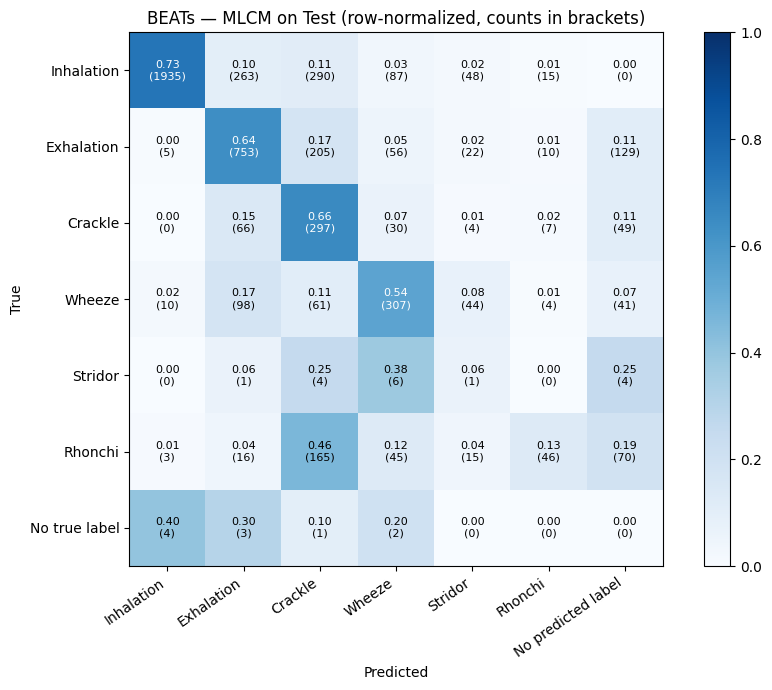

In [ ]:
# الفكرة: التنبيه لكل جلسة (143 جلسة في Test) + MLCM للأصناف الستة
# الهدف: تقييم النظام كما يُستخدم فعلياً (قرار واحد لكل جلسة فحص)، وإظهار أين يخلط النموذج بين الأصناف
# المصدر: Ilse et al., 2018 (MIL pooling) — Heydarian et al., 2022 (MLCM) — Hsu et al., 2021 (HF_Lung_V1)
import re, datetime as dt, numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score
from IPython.display import display

ROOT = '/content/drive/MyDrive'; CACHE = f'{ROOT}/crnn_cache'; RUN = f'{ROOT}/beats_5fold'
CLASSES = ['Inhalation', 'Exhalation', 'Crackle', 'Wheeze', 'Stridor', 'Rhonchi']; TS = np.arange(0.01, 1.0, 0.01)

def steth_time(n): return dt.datetime.strptime(re.match(r'steth_(\d{8}(?:_\d{2}){3})', n).group(1), '%Y%m%d_%H_%M_%S')

def sessions(names, tau=600.0):
    # trunc: نفس الطابع الزمني = جلسة واحدة | steth: تسجيلات متتالية بفاصل أقل من tau ثانية = جلسة واحدة
    sid, st = np.empty(len(names), object), []
    for i, n in enumerate(names):
        if n.startswith('trunc'): sid[i] = 'T_' + re.match(r'trunc_(\d{4}(?:-\d{2}){5})', n).group(1)
        else: st.append((steth_time(n), i))
    g, prev = -1, None
    for t, i in sorted(st):
        if prev is None or (t - prev).total_seconds() >= tau: g += 1
        sid[i], prev = f'S_{g}', t
    return sid

def steth_gaps(names):
    ts = sorted(steth_time(n) for n in names if n.startswith('steth'))
    return np.array([(b - a).total_seconds() for a, b in zip(ts[:-1], ts[1:])])

def best_thr(y, p, mode='F1'):
    H = p[None, :] >= TS[:, None]
    tp, fp, fn = (H & y).sum(1), (H & ~y).sum(1), (~H & y).sum(1)
    s = 2*tp/np.maximum(2*tp + fp + fn, 1) if mode == 'F1' else (H == y).mean(1)
    return float(TS[np.argmax(s)])

def metrics(y, p, t):
    h = p >= t; tp, fp, fn, tn = int((h & y).sum()), int((h & ~y).sum()), int((~h & y).sum()), int((~h & ~y).sum())
    pr, rc = tp/max(tp + fp, 1), tp/max(tp + fn, 1)
    return dict(Sessions=len(y), Abnormal=int(y.sum()), Threshold=t, Accuracy=(tp + tn)/len(y), Precision=pr, Recall=rc,
                Specificity=tn/max(tn + fp, 1), F1=2*pr*rc/max(pr + rc, 1e-9), AUC=roc_auc_score(y, p), TP=tp, FN=fn, FP=fp, TN=tn)

def per_session(sid, p, y, agg):
    g = pd.DataFrame(dict(s=sid, p=p, y=y)).groupby('s')
    return g.y.max().values.astype(bool), g.p.apply(agg).values

# تحميل الأسماء والـ labels والاحتمالات
ntr, nte = [np.load(f'{CACHE}/{s}_names.npy', allow_pickle=True).astype(str) for s in ['train', 'test']]
Ytr, Yte = [np.load(f'{CACHE}/{s}_Yf.npy').max(1).astype(bool) for s in ['train', 'test']]
oof, P = np.load(f'{RUN}/beats_oof_prob.npy'), np.load(f'{RUN}/beats_test_prob.npy')
fold = np.load(f'{CACHE}/train_fold.npy')

# ضبط الحالة الحدّية لقاعدة الـ 10 دقائق ثم التحقق من عدد الجلسات
tau, gt, gr = 600.0, steth_gaps(nte), steth_gaps(ntr)
print('test  steth gaps 8–15 min (s):', sorted(gt[(gt >= 480) & (gt <= 900)].astype(int)))
print('train steth gaps 8–15 min (s):', sorted(gr[(gr >= 480) & (gr <= 900)].astype(int)))
if len(set(sessions(nte, tau))) != 143:
    g1 = gt[gt >= 600].min()
    print(f'smallest test gap ≥ 10 min = {g1:.0f} s')
    if g1 <= 660: tau = g1 + 0.5
s_tr, s_te = sessions(ntr, tau), sessions(nte, tau)
mixed = int((pd.Series(fold).groupby(s_tr).nunique() > 1).sum())
print(f'rule: new session if gap ≥ {tau} s | train={len(set(s_tr))} (expected 382) | test={len(set(s_te))} (expected 143) | split across folds={mixed}')
assert len(set(s_tr)) == 382 and len(set(s_te)) == 143 and mixed == 0, 'session grouping differs — stop here'

# اختيار طريقة تجميع تسجيلات الجلسة والعتبة من OOF فقط، ثم التطبيق على Test
AGG = {'max': np.max, 'mean': np.mean, 'top3-mean': lambda x: np.sort(x)[-3:].mean()}
a_tr, a_te = Ytr[:, 2:].any(1), Yte[:, 2:].any(1)
auc_oof = {k: roc_auc_score(*per_session(s_tr, oof[:, 6], a_tr, f)) for k, f in AGG.items()}
best = max(auc_oof, key=auc_oof.get); print('OOF session AUC per pooling:', {k: round(v, 4) for k, v in auc_oof.items()}, '→', best)
y_o, p_o = per_session(s_tr, oof[:, 6], a_tr, AGG[best]); t = best_thr(y_o, p_o)
y_t, p_t = per_session(s_te, P[:, 6], a_te, AGG[best])
res = pd.DataFrame({'OOF (train sessions)': metrics(y_o, p_o, t), 'Test (official)': metrics(y_t, p_t, t)}).T
print(f'\nBEATs — Alert per session (pooling = {best}, F1-optimal OOF threshold)')
display(res[['Sessions', 'Abnormal', 'TP', 'FN', 'FP', 'TN']].astype(int))
display(res[['Threshold', 'Accuracy', 'Precision', 'Recall', 'Specificity', 'F1', 'AUC']].astype(float).round(3))
res.to_csv(f'{RUN}/beats_test_alert_session.csv')

# MLCM على Test بعتبات F1-optimal
def mlcm(Yt, Yp):
    q = Yt.shape[1]; M = np.zeros((q + 1, q + 1), int)
    for tt, pp in zip(Yt, Yp):
        T, Pp = set(np.where(tt)[0]), set(np.where(pp)[0])
        if not T:
            for c in (Pp or {q}): M[q, c] += 1
            continue
        for r in T & Pp: M[r, r] += 1
        miss, extra = T - Pp, Pp - T
        if not extra:
            for r in miss: M[r, q] += 1                    # لم يُتوقَّع الصنف
        else:
            for r in (miss or T):
                for c in extra: M[r, c] += 1               # توقّع زائد يُحسب على الأصناف الحقيقية
    return M

M = mlcm(Yte, P[:, :6] >= np.load(f'{RUN}/beats_thr_f1.npy')[:6]); N = M/np.maximum(M.sum(1, keepdims=True), 1)
fig, ax = plt.subplots(figsize=(9, 7)); im = ax.imshow(N, cmap='Blues', vmin=0, vmax=1)
ax.set_xticks(range(7)); ax.set_xticklabels(CLASSES + ['No predicted label'], rotation=35, ha='right')
ax.set_yticks(range(7)); ax.set_yticklabels(CLASSES + ['No true label'])
for i in range(7):
    for j in range(7):
        ax.text(j, i, f'{N[i, j]:.2f}\n({M[i, j]})', ha='center', va='center', fontsize=8, color='white' if N[i, j] > 0.5 else 'black')
ax.set_xlabel('Predicted'); ax.set_ylabel('True'); ax.set_title('BEATs — MLCM on Test (row-normalized, counts in brackets)')
fig.colorbar(im, fraction=0.046); fig.tight_layout(); fig.savefig(f'{RUN}/beats_test_mlcm.png', dpi=200); plt.show()
pd.DataFrame(M, index=CLASSES + ['No true label'], columns=CLASSES + ['No predicted label']).to_csv(f'{RUN}/beats_test_mlcm.csv')

In [ ]:
# الفكرة: تجربة إضافية — رفع العتبة (Threshold Moving) لـ Wheeze و Stridor و Rhonchi إلى 0.75 / 0.80
# الهدف: مقارنة موثّقة بين عتبة 0.5 والعتبتين 0.75 و0.80 وعتبات OOF الحالية، على OOF و Test
# المصدر: Zhou & Liu, 2006 (Threshold Moving, IEEE TKDE) — Lipton et al., 2014 (Optimal thresholding)
import numpy as np, pandas as pd
from sklearn.metrics import roc_auc_score
from IPython.display import display

ROOT = '/content/drive/MyDrive'; CACHE = f'{ROOT}/crnn_cache'; RUN = f'{ROOT}/beats_5fold'
CLASSES = ['Inhalation', 'Exhalation', 'Crackle', 'Wheeze', 'Stridor', 'Rhonchi']; LOW = [3, 4, 5]

# الـ labels والاحتمالات (6 أصناف) + العتبات الحالية المحفوظة من OOF
lab = lambda s: np.load(f'{CACHE}/{s}_Yf.npy').max(1)[:, :6].astype(bool)
D = {'OOF': (lab('train'), np.load(f'{RUN}/beats_oof_prob.npy')[:, :6]),
     'Test': (lab('test'), np.load(f'{RUN}/beats_test_prob.npy')[:, :6])}
t_acc, t_f1 = np.load(f'{RUN}/beats_thr_acc.npy')[:6], np.load(f'{RUN}/beats_thr_f1.npy')[:6]
print('current OOF Accuracy-optimal thresholds:', dict(zip(CLASSES, t_acc.round(2))))

def sup(v):                                    # 0.5 لكل الأصناف، و v للأصناف الثلاثة
    t = np.full(6, 0.5); t[LOW] = v; return t
SCEN = {'0.5 for all': np.full(6, 0.5),
        'Supervisor: 0.75 (W, S, R)': sup(0.75),
        'Supervisor: 0.80 (W, S, R)': sup(0.80),
        'OOF Accuracy-optimal (current)': t_acc,
        'OOF F1-optimal (current)': t_f1}

def cls_metrics(y, p, t):
    h = p >= t; tp, fp, fn, tn = (h & y).sum(), (h & ~y).sum(), (~h & y).sum(), (~h & ~y).sum()
    pr, rc = tp/max(tp + fp, 1), tp/max(tp + fn, 1)
    return dict(Accuracy=(tp + tn)/len(y), Precision=pr, Recall=rc, F1=2*pr*rc/max(pr + rc, 1e-9), AUC=roc_auc_score(y, p))

# جدول Macro للأصناف الستة + جدول الأصناف الثلاثة، لكل سيناريو عتبات
macro, low = [], []
for split, (Y, P) in D.items():
    for name, t in SCEN.items():
        m = pd.DataFrame([cls_metrics(Y[:, i], P[:, i], t[i]) for i in range(6)], index=CLASSES)
        macro.append(dict(Split=split, Thresholds=name, **m.mean().rename(lambda c: 'Macro-' + c)))
        for i in LOW:
            low.append(dict(Split=split, Thresholds=name, Class=CLASSES[i], Threshold=t[i], **m.iloc[i]))
macro = pd.DataFrame(macro).set_index(['Split', 'Thresholds'])
low = pd.DataFrame(low).set_index(['Split', 'Thresholds', 'Class'])
print('\nMacro — 6 classes'); display(macro.round(3))
print('\nWheeze / Stridor / Rhonchi'); display(low.round(3))
macro.to_csv(f'{RUN}/beats_threshold_scenarios_macro.csv'); low.to_csv(f'{RUN}/beats_threshold_scenarios_classes.csv')

FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/crnn_cache/train_Yf.npy'

In [ ]:
# الفكرة: تجربة إضافية — رفع العتبة (Threshold Moving) لـ Wheeze و Stridor و Rhonchi إلى 0.75 / 0.80
# الهدف: مقارنة موثّقة بين عتبة 0.5 والعتبتين 0.75 و0.80 وعتبات OOF الحالية، على OOF و Test
# المصدر: Zhou & Liu, 2006 (Threshold Moving, IEEE TKDE) — Lipton et al., 2014 (Optimal thresholding)
import os, numpy as np, pandas as pd
from sklearn.metrics import roc_auc_score
from IPython.display import display
from google.colab import drive
drive.mount('/content/drive')

ROOT = '/content/drive/MyDrive'; CACHE = f'{ROOT}/crnn_cache'; RUN = f'{ROOT}/beats_5fold'
CLASSES = ['Inhalation', 'Exhalation', 'Crackle', 'Wheeze', 'Stridor', 'Rhonchi']; LOW = [3, 4, 5]

# فحص وجود الملفات قبل التحميل
need = [f'{CACHE}/train_Yf.npy', f'{CACHE}/test_Yf.npy', f'{RUN}/beats_oof_prob.npy',
        f'{RUN}/beats_test_prob.npy', f'{RUN}/beats_thr_acc.npy', f'{RUN}/beats_thr_f1.npy']
miss = [p for p in need if not os.path.exists(p)]
if miss:
    print('missing:', miss)
    for d in [CACHE, RUN]: print(f'\n{d}:', sorted(os.listdir(d)) if os.path.isdir(d) else 'folder not found')
    raise SystemExit('stop: files not found')

# الـ labels والاحتمالات (6 أصناف) + العتبات الحالية المحفوظة من OOF
lab = lambda s: np.load(f'{CACHE}/{s}_Yf.npy').max(1)[:, :6].astype(bool)
D = {'OOF': (lab('train'), np.load(f'{RUN}/beats_oof_prob.npy')[:, :6]),
     'Test': (lab('test'), np.load(f'{RUN}/beats_test_prob.npy')[:, :6])}
t_acc, t_f1 = np.load(f'{RUN}/beats_thr_acc.npy')[:6], np.load(f'{RUN}/beats_thr_f1.npy')[:6]
print('current OOF Accuracy-optimal thresholds:', dict(zip(CLASSES, t_acc.round(2))))

def sup(v):                                    # 0.5 لكل الأصناف، و v للأصناف الثلاثة
    t = np.full(6, 0.5); t[LOW] = v; return t
SCEN = {'0.5 for all': np.full(6, 0.5),
        'Supervisor: 0.75 (W, S, R)': sup(0.75),
        'Supervisor: 0.80 (W, S, R)': sup(0.80),
        'OOF Accuracy-optimal (current)': t_acc,
        'OOF F1-optimal (current)': t_f1}

def cls_metrics(y, p, t):
    h = p >= t; tp, fp, fn, tn = (h & y).sum(), (h & ~y).sum(), (~h & y).sum(), (~h & ~y).sum()
    pr, rc = tp/max(tp + fp, 1), tp/max(tp + fn, 1)
    return dict(Accuracy=(tp + tn)/len(y), Precision=pr, Recall=rc, F1=2*pr*rc/max(pr + rc, 1e-9), AUC=roc_auc_score(y, p))

# جدول Macro للأصناف الستة + جدول الأصناف الثلاثة، لكل سيناريو عتبات
macro, low = [], []
for split, (Y, P) in D.items():
    for name, t in SCEN.items():
        m = pd.DataFrame([cls_metrics(Y[:, i], P[:, i], t[i]) for i in range(6)], index=CLASSES)
        macro.append(dict(Split=split, Thresholds=name, **m.mean().rename(lambda c: 'Macro-' + c)))
        for i in LOW:
            low.append(dict(Split=split, Thresholds=name, Class=CLASSES[i], Threshold=t[i], **m.iloc[i]))
macro = pd.DataFrame(macro).set_index(['Split', 'Thresholds'])
low = pd.DataFrame(low).set_index(['Split', 'Thresholds', 'Class'])
print('\nMacro — 6 classes'); display(macro.round(3))
print('\nWheeze / Stridor / Rhonchi'); display(low.round(3))
macro.to_csv(f'{RUN}/beats_threshold_scenarios_macro.csv'); low.to_csv(f'{RUN}/beats_threshold_scenarios_classes.csv')

Mounted at /content/drive
current OOF Accuracy-optimal thresholds: {'Inhalation': np.float64(0.39), 'Exhalation': np.float64(0.66), 'Crackle': np.float64(0.71), 'Wheeze': np.float64(0.8), 'Stridor': np.float64(0.97), 'Rhonchi': np.float64(0.86)}

Macro — 6 classes


Macro-Accuracy  Macro-Precision  \
Split Thresholds                                                        
OOF   0.5 for all                              0.864            0.653   
      Supervisor: 0.75 (W, S, R)               0.871            0.689   
      Supervisor: 0.80 (W, S, R)               0.871            0.696   
      OOF Accuracy-optimal (current)           0.877            0.756   
      OOF F1-optimal (current)                 0.866            0.660   
Test  0.5 for all                              0.850            0.571   
      Supervisor: 0.75 (W, S, R)               0.852            0.605   
      Supervisor: 0.80 (W, S, R)               0.852            0.621   
      OOF Accuracy-optimal (current)           0.877            0.642   
      OOF F1-optimal (current)                 0.855            0.584   

                                      Macro-Recall  Macro-F1  Macro-AUC  
Split Thresholds                                                         
OOF   0.5 for all                            0.760     0.701      0.867  
      Supervisor: 0.75 (W, S, R)             0.719     0.699      0.867  
      Supervisor: 0.80 (W, S, R)             0.706     0.695      0.867  
      OOF Accuracy-optimal (current)         0.656     0.676      0.867  
      OOF F1-optimal (current)               0.761     0.705      0.867  
Test  0.5 for all                            0.613     0.551      0.828  
      Supervisor: 0.75 (W, S, R)             0.572     0.533      0.828  
      Supervisor: 0.80 (W, S, R)             0.564     0.530      0.828  
      OOF Accuracy-optimal (current)         0.508     0.522      0.828  
      OOF F1-optimal (current)               0.599     0.541      0.828


Wheeze / Stridor / Rhonchi


Threshold  Accuracy  Precision  \
Split Thresholds                     Class                                     
OOF   0.5 for all                    Wheeze        0.50     0.829      0.668   
                                     Stridor       0.50     0.954      0.294   
                                     Rhonchi       0.50     0.898      0.558   
      Supervisor: 0.75 (W, S, R)     Wheeze        0.75     0.844      0.735   
                                     Stridor       0.75     0.963      0.388   
                                     Rhonchi       0.75     0.911      0.617   
      Supervisor: 0.80 (W, S, R)     Wheeze        0.80     0.845      0.751   
                                     Stridor       0.80     0.964      0.393   
                                     Rhonchi       0.80     0.912      0.633   
      OOF Accuracy-optimal (current) Wheeze        0.80     0.845      0.751   
                                     Stridor       0.97     0.969      0.622   
                                     Rhonchi       0.86     0.916      0.665   
      OOF F1-optimal (current)       Wheeze        0.43     0.825      0.654   
                                     Stridor       0.36     0.949      0.280   
                                     Rhonchi       0.69     0.908      0.600   
Test  0.5 for all                    Wheeze        0.50     0.878      0.699   
                                     Stridor       0.50     0.977      0.029   
                                     Rhonchi       0.50     0.868      0.708   
      Supervisor: 0.75 (W, S, R)     Wheeze        0.75     0.882      0.820   
                                     Stridor       0.75     0.989      0.091   
                                     Rhonchi       0.75     0.861      0.727   
      Supervisor: 0.80 (W, S, R)     Wheeze        0.80     0.880      0.851   
                                     Stridor       0.80     0.991      0.125   
                                     Rhonchi       0.80     0.862      0.760   
      OOF Accuracy-optimal (current) Wheeze        0.80     0.880      0.851   
                                     Stridor       0.97     0.993      0.000   
                                     Rhonchi       0.86     0.863      0.822   
      OOF F1-optimal (current)       Wheeze        0.43     0.879      0.690   
                                     Stridor       0.36     0.959      0.014   
                                     Rhonchi       0.69     0.864      0.742   

                                              Recall     F1    AUC  
Split Thresholds                     Class                          
OOF   0.5 for all                    Wheeze    0.812  0.733  0.904  
                                     Stridor   0.308  0.301  0.829  
                                     Rhonchi   0.765  0.645  0.930  
      Supervisor: 0.75 (W, S, R)     Wheeze    0.717  0.726  0.904  
                                     Stridor   0.233  0.291  0.829  
                                     Rhonchi   0.689  0.651  0.930  
      Supervisor: 0.80 (W, S, R)     Wheeze    0.692  0.720  0.904  
                                     Stridor   0.217  0.280  0.829  
                                     Rhonchi   0.655  0.643  0.930  
      OOF Accuracy-optimal (current) Wheeze    0.692  0.720  0.904  
                                     Stridor   0.111  0.188  0.829  
                                     Rhonchi   0.614  0.639  0.930  
      OOF F1-optimal (current)       Wheeze    0.839  0.735  0.904  
                                     Stridor   0.372  0.319  0.829  
                                     Rhonchi   0.714  0.652  0.930  
Test  0.5 for all                    Wheeze    0.721  0.710  0.922  
                                     Stridor   0.083  0.043  0.821  
                                     Rhonchi   0.213  0.327  0.696  
      Supervisor: 0.75 (W, S, R)     Wheeze    0.551  0.659  0.922  
                                    

In [ ]:
# Idea: verify the frame-labeling rule used in train_Yf.npy
# Goal: confirm that a frame = 1 when its time falls inside a labeled event (start <= t <= end)
# Source: Hsu et al., 2021 (HF_Lung_V1, 938 frames per 15-s recording)
import os, subprocess, numpy as np
from google.colab import drive
drive.mount('/content/drive')

REPO, RAWD = '/content/HF_Lung_V1', '/content/hf_raw'
CACHE = '/content/drive/MyDrive/crnn_cache'
CLS = {'I': 0, 'E': 1, 'D': 2, 'W': 3, 'S': 4, 'R': 5}   # Inhalation, Exhalation, Crackle, Wheeze, Stridor, Rhonchi
T, HOP = 938, 64 / 4000                                   # 938 frames, 16 ms each

# Download and extract the train set if not present
if not os.path.exists(f'{RAWD}/train/.done'):
    if not os.path.exists(REPO):
        subprocess.run(['git', 'clone', '-q', '--depth', '1', 'https://gitlab.com/techsupportHF/HF_Lung_V1.git', REPO], check=True)
    subprocess.run('apt-get -qq install -y p7zip-full', shell=True)
    subprocess.run(['7z', 'x', '-y', '-bso0', '-bsp0', f'{REPO}/train.7z.001', f'-o{RAWD}/train'], check=True)
    open(f'{RAWD}/train/.done', 'w').close()

def stem(x): return os.path.splitext(os.path.basename(str(x)))[0]
lab = {f[:-len('_label.txt')]: os.path.join(d, f) for d, _, fs in os.walk(f'{RAWD}/train') for f in fs if f.endswith('_label.txt')}

def secs(s):                                              # 'hh:mm:ss.fff' -> seconds
    h, m, x = s.split(':'); return int(h) * 3600 + int(m) * 60 + float(x)

def rebuild(path):                                        # apply the rule: frame time inside [start, end]
    y, t, other = np.zeros((T, 6), bool), np.arange(T) * HOP, set()
    for line in open(path):
        p = line.split()
        if len(p) < 3: continue
        if p[0] not in CLS: other.add(p[0]); continue
        y[(t >= secs(p[1])) & (t <= secs(p[2])), CLS[p[0]]] = True
    return y, other

# Compare on 200 random recordings
names = np.load(f'{CACHE}/train_names.npy', allow_pickle=True)
Yf = np.load(f'{CACHE}/train_Yf.npy', mmap_mode='r')
print('example label file:', open(lab[stem(names[0])]).read()[:200])
match, unknown = [], set()
for i in np.random.default_rng(0).choice(len(names), 200, replace=False):
    y, o = rebuild(lab[stem(names[i])]); unknown |= o
    match.append((y == Yf[i].astype(bool)).mean(0))
match = np.array(match)
for c, k in zip(['Inhalation', 'Exhalation', 'Crackle', 'Wheeze', 'Stridor', 'Rhonchi'], range(6)):
    print(f'{c:<11} frame agreement: {match[:, k].mean()*100:.2f}%')
print('labels not in the 6 classes:', unknown or 'none')

ValueError: mount failed

In [ ]:
# Idea: rebuild the Test waveform cache (int16, 4 kHz) on Colab local disk
# Goal: provide /content/wav_cache/test_wav.npy in the same order as test_names.npy for Grad-CAM
# Source: Hsu et al., 2021 (HF_Lung_V1, gitlab.com/techsupportHF/HF_Lung_V1)
import os, shutil, subprocess, numpy as np, soundfile as sf
from concurrent.futures import ThreadPoolExecutor
from tqdm.auto import tqdm

REPO, RAWD, OUT = '/content/HF_Lung_V1', '/content/hf_raw', '/content/wav_cache'
CACHE, L = '/content/drive/MyDrive/crnn_cache', 60000
os.makedirs(OUT, exist_ok=True)

if not os.path.exists(REPO):
    subprocess.run(['git', 'clone', '-q', '--depth', '1', 'https://gitlab.com/techsupportHF/HF_Lung_V1.git', REPO], check=True)
if not shutil.which('7z'):
    subprocess.run('apt-get -qq install -y p7zip-full', shell=True, check=True)
if not os.path.exists(f'{RAWD}/test/.done'):
    subprocess.run(['7z', 'x', '-y', '-bso0', '-bsp0', f'{REPO}/test.7z.001', f'-o{RAWD}/test'], check=True)
    open(f'{RAWD}/test/.done', 'w').close()

stem = lambda x: os.path.splitext(os.path.basename(str(x)))[0]
def read(path):
    y, sr = sf.read(path, dtype='int16', always_2d=True); y = y[:, 0]
    out = np.zeros(L, np.int16); out[:min(len(y), L)] = y[:L]
    return out, sr, len(y)

names = np.load(f'{CACHE}/test_names.npy', allow_pickle=True)
idx = {stem(f): os.path.join(d, f) for d, _, fs in os.walk(f'{RAWD}/test') for f in fs if f.lower().endswith('.wav')}
miss = [n for n in names if stem(n) not in idx]
assert not miss, f'{len(miss)} missing, e.g. {miss[:3]}'

dst = f'{OUT}/test_wav.npy'
W = np.lib.format.open_memmap(dst + '.tmp', mode='w+', dtype=np.int16, shape=(len(names), L))
srs, lens = set(), []
with ThreadPoolExecutor(8) as ex:
    for i, (y, sr, n) in enumerate(tqdm(ex.map(read, [idx[stem(n)] for n in names]), total=len(names), desc='test')):
        W[i] = y; srs.add(sr); lens.append(n)
W.flush(); del W; os.replace(dst + '.tmp', dst)
print(f'test_wav.npy: shape={np.load(dst, mmap_mode="r").shape} | sr={srs} | length min/max={min(lens)}/{max(lens)}')

test:   0%|          | 0/1956 [00:00<?, ?it/s]

test_wav.npy: shape=(1956, 60000) | sr={4000} | length min/max=60000/60000


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
wav files ready: {'Wheeze': 'steth_20190920_20_41_45', 'Crackle': 'steth_20190812_11_03_39'}


/usr/local/lib/python3.13/dist-packages/torch/nn/utils/weight_norm.py:144: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)


fold models used: [0, 1]


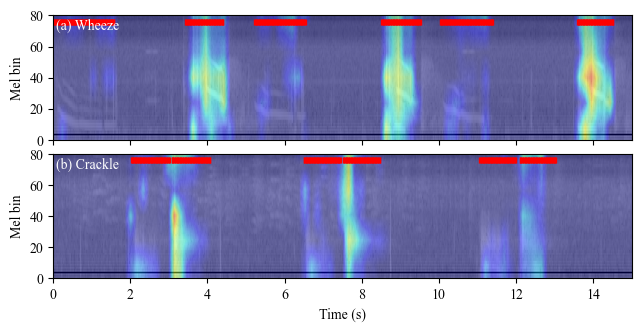

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# Idea: self-contained Grad-CAM for Fig. 3 (same method as before: last BEATs layer, folds 0 and 1, same two Test recordings)
# Goal: rebuild the figure in the journal format (16 x 8 cm, Times New Roman 10 pt, 300 dpi) without the full wav cache
# Source: Selvaraju et al., ICCV 2017 (Grad-CAM); Chen et al., ICML 2023 (BEATs); journal_Format.docx (Ver. 2026.10.1)
import os, sys, glob, subprocess, numpy as np, torch, torch.nn as nn, torch.nn.functional as F, torchaudio, soundfile as sf
import matplotlib.pyplot as plt
from matplotlib import font_manager
from google.colab import drive, files
drive.mount('/content/drive')
ROOT = '/content/drive/MyDrive'; CACHE = f'{ROOT}/crnn_cache'; RUN = f'{ROOT}/beats_5fold'
sys.path.insert(0, f'{ROOT}/models/beats_code')
from BEATs import BEATs, BEATsConfig
dev = 'cuda'
CLASSES = ['Inhalation', 'Exhalation', 'Crackle', 'Wheeze', 'Stridor', 'Rhonchi']
STEMS = {3: 'steth_20190920_20_41_45', 2: 'steth_20190812_11_03_39'}   # Wheeze, Crackle (same picks as the paper)

# 1) get only the two Test wav files from the official HF_Lung_V1 repository
if not os.path.exists('/content/HF_Lung_V1'):
    subprocess.run('git clone -q --depth 1 https://gitlab.com/techsupportHF/HF_Lung_V1.git /content/HF_Lung_V1', shell=True)
subprocess.run('which 7z || apt-get -qq install -y p7zip-full > /dev/null', shell=True)
arc = sorted(glob.glob('/content/HF_Lung_V1/**/test.7z.001', recursive=True))
assert arc, 'test.7z.001 not found - check the repository download'
subprocess.run(f'7z e "{arc[0]}" -o/content/hf_two -r {" ".join(s + ".wav" for s in STEMS.values())} -y > /dev/null', shell=True)
wavs = {}
for c, s in STEMS.items():
    x, sr = sf.read(f'/content/hf_two/{s}.wav', dtype='float32'); x = x if x.ndim == 1 else x[:, 0]
    assert sr == 4000, sr
    wavs[c] = np.pad(x, (0, max(0, 60000 - len(x))))[:60000]
print('wav files ready:', {CLASSES[c]: s for c, s in STEMS.items()})

# 2) model with the Grad-CAM forward (unchanged from the original cell)
class BEATsFrame(nn.Module):
    def __init__(self, beats, n_out=7, t_out=938, p=0.1):
        super().__init__()
        self.beats, self.t_out = beats, t_out
        self.resample = torchaudio.transforms.Resample(4000, 16000)
        d = beats.cfg.encoder_embed_dim
        self.norm, self.drop, self.fc = nn.LayerNorm(d), nn.Dropout(p), nn.Linear(d, n_out)
    @torch.no_grad()
    def fbank(self, wav):
        return self.beats.preprocess(self.resample(wav.float()))
    def forward_cam(self, wav, c):
        fb = self.fbank(wav); b = self.beats
        x = b.patch_embedding(fb.unsqueeze(1)); Tt, Ff = x.shape[2], x.shape[3]
        x = b.layer_norm(x.flatten(2).transpose(1, 2))
        if b.post_extract_proj is not None: x = b.post_extract_proj(x)
        A, _ = b.encoder(b.dropout_input(x), padding_mask=None)
        A.retain_grad()
        h = A.reshape(1, Tt, Ff, -1).mean(2)
        z = F.interpolate(self.fc(self.drop(self.norm(h))).transpose(1, 2), size=self.t_out,
                          mode='linear', align_corners=False).transpose(1, 2)
        z[0, :, c].max().backward()
        w = A.grad.mean(1, keepdim=True)
        cam = F.relu((A * w).sum(-1)).reshape(1, 1, Tt, Ff)
        cam = F.interpolate(cam, size=fb.shape[1:], mode='bilinear', align_corners=False)[0, 0]
        return fb[0].cpu().numpy(), cam.detach().cpu().numpy()

ck = torch.load(f'{ROOT}/models/BEATs_iter3_plus_AS2M.pt', map_location='cpu', weights_only=False)
beats = BEATs(BEATsConfig(ck['cfg'])); beats.load_state_dict(ck['model'])
model = BEATsFrame(beats).to(dev).eval()
names = np.load(f'{CACHE}/test_names.npy', allow_pickle=True).astype(str)
idx = {c: int(np.where(np.char.find(names, s) >= 0)[0][0]) for c, s in STEMS.items()}
Yf = np.load(f'{CACHE}/test_Yf.npy', mmap_mode='r')
FOLDS = [k for k in (0, 1) if os.path.exists(f'{RUN}/fold{k}_best.pt')]
print('fold models used:', FOLDS)

cams = {c: [] for c in STEMS}; fbs = {}
for k in FOLDS:
    sd = torch.load(f'{RUN}/fold{k}_best.pt', map_location=dev)
    model.load_state_dict({n: v.float() if v.is_floating_point() else v for n, v in sd.items()})
    for c in STEMS:
        model.zero_grad(set_to_none=True)
        fb, cam = model.forward_cam(torch.from_numpy(wavs[c])[None].to(dev), c)
        cams[c].append(cam / (cam.max() + 1e-8)); fbs[c] = fb

# 3) plot in the journal format
subprocess.run('echo ttf-mscorefonts-installer msttcorefonts/accepted-mscorefonts-eula select true | debconf-set-selections && '
               'apt-get -qq install -y ttf-mscorefonts-installer > /dev/null 2>&1', shell=True)
for f in font_manager.findSystemFonts(): font_manager.fontManager.addfont(f)
plt.rcParams.update({'font.family': 'Times New Roman', 'font.size': 10, 'axes.labelsize': 10,
                     'xtick.labelsize': 10, 'ytick.labelsize': 10})
cm = 1 / 2.54
fig, axes = plt.subplots(2, 1, figsize=(16 * cm, 8 * cm), sharex=True)
for ax, c, lab in zip(axes, [3, 2], ['(a) Wheeze', '(b) Crackle']):
    cam = np.mean(cams[c], 0)
    ax.imshow(fbs[c].T, origin='lower', aspect='auto', cmap='gray', extent=[0, 15, 0, 128])
    ax.imshow(cam.T, origin='lower', aspect='auto', cmap='jet', alpha=0.45, extent=[0, 15, 0, 128], vmin=0, vmax=1)
    on = np.asarray(Yf[idx[c], :, c]) == 1; t = np.arange(938) * 64 / 4000
    ax.plot(t[on], np.full(on.sum(), 76), 'r|', ms=5)
    ax.set_ylim(0, 80); ax.set_ylabel('Mel bin')
    ax.text(0.005, 0.97, lab, transform=ax.transAxes, va='top', ha='left', color='white')
axes[-1].set_xlabel('Time (s)')
fig.tight_layout(pad=0.3, h_pad=0.4)
fig.savefig(f'{RUN}/fig3_gradcam_journal_300dpi.png', dpi=300, facecolor='white')
plt.show(); files.download(f'{RUN}/fig3_gradcam_journal_300dpi.png')

In [ ]:
# Idea: Inventory of saved BEATs / CNN-BiGRU artifacts before frame- and event-level evaluation
# Goal: Confirm which checkpoints, code and test-order files exist in Drive
# Source: Mesaros, Heittola & Virtanen 2016, Applied Sciences 6(6):162 (SED metrics)
from google.colab import drive
drive.mount('/content/drive')
import os, glob
root = '/content/drive/MyDrive'
for d in ['beats_5fold', 'models', 'models/beats_code', 'crnn_cache', 'External_Validation']:
    p = os.path.join(root, d)
    print(f'\n== {d} ==')
    if os.path.isdir(p):
        for f in sorted(os.listdir(p))[:40]:
            fp = os.path.join(p, f)
            print(f'  {f:45s} {os.path.getsize(fp)/1e6:8.1f} MB' if os.path.isfile(fp) else f'  {f}/')
    else:
        print('  (missing)')
print('\n== folders containing "bigru" or "crnn" ==')
for p in glob.glob(root + '/*'):
    if any(k in p.lower() for k in ['bigru', 'crnn', 'cnn']):
        print(' ', p, '->', sorted(os.listdir(p))[:15])

In [ ]:
# Idea: Rebuild HF_Lung_V1 test audio + event annotations for frame/event-level evaluation
# Goal: Inspect label-file format (onset/offset per event) before building frame-level ground truth
# Source: Hsu et al. 2021, PLOS ONE 16(7):e0254134 (HF_Lung_V1, official GitLab release)
from google.colab import drive
drive.mount('/content/drive')
import os, glob, subprocess, numpy as np, torch
print('GPU:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'NONE')
os.chdir('/content')
if not os.path.isdir('/content/HF_Lung_V1'):
    subprocess.run('git clone --depth 1 https://gitlab.com/techsupportHF/HF_Lung_V1.git', shell=True, check=True)
os.chdir('/content/HF_Lung_V1')
if not glob.glob('/content/HF_Lung_V1/**/*_label.txt', recursive=True) or len(glob.glob('/content/HF_Lung_V1/**/test/**/*.wav', recursive=True)) == 0:
    subprocess.run('7z x -y test.7z.001 > /dev/null', shell=True, check=True)
wavs = sorted(glob.glob('/content/HF_Lung_V1/**/*.wav', recursive=True))
labs = sorted(glob.glob('/content/HF_Lung_V1/**/*_label.txt', recursive=True))
test_names = np.load('/content/drive/MyDrive/crnn_cache/test_names.npy', allow_pickle=True)
print('wav files:', len(wavs), '| label files:', len(labs), '| test_names:', len(test_names))
print('first test name:', test_names[0])
for f in labs[:3]:
    print('\n---', os.path.relpath(f, '/content/HF_Lung_V1'))
    print(open(f).read()[:400])
tokens = {}
for f in labs:
    for line in open(f):
        p = line.split()
        if p: tokens[p[0]] = tokens.get(p[0], 0) + 1
print('\nlabel tokens and event counts:', tokens)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
GPU: NONE
wav files: 1956 | label files: 1956 | test_names: 1956
first test name: steth_20190801_09_46_05

--- test/steth_20190801_09_46_05_label.txt
I 00:00:01.120 00:00:01.937
D 00:00:01.120 00:00:01.937
I 00:00:03.340 00:00:04.157
D 00:00:03.340 00:00:04.157
I 00:00:05.674 00:00:06.491
D 00:00:05.674 00:00:06.491
I 00:00:07.855 00:00:08.805
D 00:00:07.855 00:00:08.805
I 00:00:10.018 00:00:10.968
D 00:00:10.018 00:00:10.968
I 00:00:12.105 00:00:13.055
D 00:00:12.105 00:00:13.055


--- test/steth_20190801_09_46_26_label.txt
I 00:00:00.000 00:00:00.856
D 00:00:00.000 00:00:00.856
I 00:00:01.992 00:00:02.848
D 00:00:01.992 00:00:02.848
I 00:00:04.382 00:00:05.238
D 00:00:04.382 00:00:05.238
I 00:00:06.640 00:00:07.496
D 00:00:06.640 00:00:07.496
I 00:00:08.803 00:00:09.659
D 00:00:08.803 00:00:09.659
I 00:00:10.966 00:00:11.822
D 00:00:10.966 00:00:11.822
I 00

In [ ]:
# Idea: Frame-level and event-level ground truth for HF_Lung_V1 test set (938 frames x 6 classes)
# Goal: Reference labels for frame/event evaluation; frame k centred at k*16 ms (hop 64 @ 4 kHz, centre padding)
# Source: Hsu et al. 2021 PLOS ONE (HF_Lung_V1 frame convention); Mesaros et al. 2016 Appl. Sci. (SED metrics)
import os, json, numpy as np
SRC = '/content/HF_Lung_V1/test'
OUT = '/content/drive/MyDrive/beats_5fold/frame_eval'
os.makedirs(OUT, exist_ok=True)
CLASSES = ['I', 'E', 'D', 'Wheeze', 'Stridor', 'Rhonchi']
NAMES = ['Inhalation', 'Exhalation', 'Crackle', 'Wheeze', 'Stridor', 'Rhonchi']
N_FR, HOP_S = 938, 64 / 4000
centres = np.arange(N_FR) * HOP_S                      # frame k centre time in seconds

def to_sec(t):
    h, m, s = t.split(':')
    return int(h) * 3600 + int(m) * 60 + float(s)

test_names = np.load('/content/drive/MyDrive/crnn_cache/test_names.npy', allow_pickle=True)
gt = np.zeros((len(test_names), N_FR, 6), dtype=np.uint8)
events = []                                            # per recording: list of (class_idx, onset, offset)
for i, n in enumerate(test_names):
    ev = []
    for line in open(f'{SRC}/{n}_label.txt'):
        p = line.split()
        if len(p) != 3 or p[0] not in CLASSES:
            continue
        c, on, off = CLASSES.index(p[0]), to_sec(p[1]), to_sec(p[2])
        ev.append((c, on, off))
        gt[i, (centres >= on) & (centres <= off), c] = 1
    events.append(ev)

np.save(f'{OUT}/test_frame_gt.npy', gt)
json.dump(events, open(f'{OUT}/test_events.json', 'w'))
print('frame GT shape:', gt.shape)
for c, nm in enumerate(NAMES):
    n_ev = sum(1 for ev in events for e in ev if e[0] == c)
    dur = [e[2] - e[1] for ev in events for e in ev if e[0] == c]
    print(f'{nm:11s} events {n_ev:5d} | positive frames {gt[:, :, c].mean()*100:5.2f}% | '
          f'median duration {np.median(dur) if dur else 0:.2f} s')

frame GT shape: (1956, 938, 6)
Inhalation  events  6872 | positive frames 21.68% | median duration 0.89 s
Exhalation  events  2748 | positive frames  9.17% | median duration 0.88 s
Crackle     events  1812 | positive frames  5.58% | median duration 0.86 s
Wheeze      events  1430 | positive frames  3.88% | median duration 0.78 s
Stridor     events    29 | positive frames  0.07% | median duration 0.61 s
Rhonchi     events   960 | positive frames  2.38% | median duration 0.70 s


In [ ]:

# Idea: Inspect saved BEATs fold checkpoint (layer names/shapes) to rebuild the exact inference model
# Goal: Match head structure (LayerNorm -> Dropout -> Linear(7)) and config before frame-level inference
# Source: Chen et al. 2023, BEATs (ICML), official unilm code; fold0_best.pt from our 5-fold training
import torch
ck = torch.load('/content/drive/MyDrive/beats_5fold/fold0_best.pt', map_location='cpu', weights_only=False)
print('top-level type:', type(ck))
if isinstance(ck, dict):
    print('top-level keys:', list(ck.keys())[:20])
    sd = ck.get('model', ck.get('state_dict', ck))
    for k in [k for k in sd if not k.startswith('beats.encoder.layers') and 'encoder.layers' not in k][:40]:
        v = sd[k]
        print(f'{k:60s} {tuple(v.shape) if hasattr(v, "shape") else v}')
    print('total tensors:', len(sd))
    for k in ['cfg', 'epoch', 'config', 'args', 'hp']:
        if k in ck: print(k, '=>', ck[k] if not hasattr(ck[k], 'keys') else dict(list(ck[k].items())[:30]))

top-level type: <class 'dict'>
top-level keys: ['beats.post_extract_proj.weight', 'beats.post_extract_proj.bias', 'beats.patch_embedding.weight', 'beats.encoder.pos_conv.0.bias', 'beats.encoder.pos_conv.0.weight_g', 'beats.encoder.pos_conv.0.weight_v', 'beats.encoder.layers.0.self_attn.grep_a', 'beats.encoder.layers.0.self_attn.relative_attention_bias.weight', 'beats.encoder.layers.0.self_attn.k_proj.weight', 'beats.encoder.layers.0.self_attn.k_proj.bias', 'beats.encoder.layers.0.self_attn.v_proj.weight', 'beats.encoder.layers.0.self_attn.v_proj.bias', 'beats.encoder.layers.0.self_attn.q_proj.weight', 'beats.encoder.layers.0.self_attn.q_proj.bias', 'beats.encoder.layers.0.self_attn.out_proj.weight', 'beats.encoder.layers.0.self_attn.out_proj.bias', 'beats.encoder.layers.0.self_attn.grep_linear.weight', 'beats.encoder.layers.0.self_attn.grep_linear.bias', 'beats.encoder.layers.0.self_attn_layer_norm.weight', 'beats.encoder.layers.0.self_attn_layer_norm.bias']
beats.post_extract_proj.wei

In [ ]:
# Idea: Rebuild BEATs + head from fold checkpoints and identify the exact interpolation/pooling used in training
# Goal: Reproduce saved recording-level probabilities (repro_test_prob_folds01.npy) before frame-level evaluation
# Source: Chen et al. 2023 BEATs (ICML), official unilm code; our training pipeline (frame BCE + clip = max of avg-pool k=9)
import sys, numpy as np, torch, torch.nn as nn, torch.nn.functional as F, soundfile as sf
sys.path.insert(0, '/content/drive/MyDrive/models/beats_code')
from BEATs import BEATs, BEATsConfig
D = '/content/drive/MyDrive'
base = torch.load(f'{D}/models/BEATs_iter3_plus_AS2M.pt', map_location='cpu', weights_only=False)
cfg = BEATsConfig(base['cfg']); cfg.finetuned_model = False

class BeatsFrame(nn.Module):
    def __init__(self):
        super().__init__()
        self.beats = BEATs(cfg)
        self.resample = nn.Module(); self.resample.register_buffer('kernel', torch.zeros(4, 1, 15))
        self.norm = nn.LayerNorm(768); self.fc = nn.Linear(768, 7)
    def up4(self, x):                                   # polyphase 4 -> 16 kHz: (B,T) -> (B,4T)
        y = F.conv1d(x[:, None], self.resample.kernel, padding=7)
        return y.transpose(1, 2).reshape(x.shape[0], -1)
    def forward(self, wav4k):                           # wav4k float in [-1, 1], (B, 60000)
        x = self.up4(wav4k)
        feats, _ = self.beats.extract_features(x, padding_mask=torch.zeros_like(x, dtype=torch.bool))
        B = feats.shape[0]
        h = feats.reshape(B, -1, 8, feats.shape[-1]).mean(2)   # (B, 93, 768): mean over frequency patches
        return self.fc(self.norm(h))                           # (B, 93, 7) logits

def load(fold):
    m = BeatsFrame(); sd = torch.load(f'{D}/beats_5fold/fold{fold}_best.pt', map_location='cpu', weights_only=False)
    r = m.load_state_dict(sd, strict=False); print(f'fold{fold} missing:', len(r.missing_keys), r.missing_keys[:3], '| unexpected:', len(r.unexpected_keys))
    return m.eval()

names = np.load(f'{D}/crnn_cache/test_names.npy', allow_pickle=True)
def read(n):
    w, _ = sf.read(f'/content/HF_Lung_V1/test/{n}.wav', dtype='int16')
    w = (w[:, 0] if w.ndim > 1 else w).astype(np.float32) / 32768.0
    return np.pad(w, (0, max(0, 60000 - len(w))))[:60000]

idx = list(range(8))
X = torch.tensor(np.stack([read(names[i]) for i in idx]))
models = [load(0), load(1)]
with torch.no_grad():
    L = torch.stack([m(X) for m in models])            # (2, B, 93, 7)
ref = np.load(f'{D}/External_Validation/repro_test_prob_folds01.npy')
print('saved repro shape:', ref.shape)
ref8 = ref[idx] if ref.shape[0] == 1956 else ref[:, idx].mean(0)

def clip_prob(L, align, pad, cip):
    z = F.interpolate(L.flatten(0, 1).transpose(1, 2), size=938, mode='linear', align_corners=align)  # (2B, 7, 938)
    p = torch.sigmoid(z)
    p = F.avg_pool1d(p, 9, stride=1, padding=pad, count_include_pad=cip) if pad else F.avg_pool1d(p, 9, stride=1)
    return p.max(-1).values.reshape(2, len(idx), 7).mean(0).numpy()

for align in [False, True]:
    for pad, cip in [(4, True), (4, False), (0, True)]:
        P = clip_prob(L, align, pad, cip)
        r = np.corrcoef(P[:, :ref8.shape[1]].ravel(), ref8.ravel())[0, 1]
        print(f'align_corners={align!s:5s} pad={pad} count_include_pad={cip!s:5s} | r={r:.6f} | max|diff|={np.abs(P[:, :ref8.shape[1]] - ref8).max():.5f}')

/usr/local/lib/python3.13/dist-packages/torch/nn/utils/weight_norm.py:145: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)


fold0 missing: 0 [] | unexpected: 0
fold1 missing: 0 [] | unexpected: 0
saved repro shape: (2, 1956, 7)
align_corners=False pad=4 count_include_pad=True  | r=0.999998 | max|diff|=0.00441
align_corners=False pad=4 count_include_pad=False | r=0.999998 | max|diff|=0.00441
align_corners=False pad=0 count_include_pad=True  | r=0.999998 | max|diff|=0.00441
align_corners=True  pad=4 count_include_pad=True  | r=0.999998 | max|diff|=0.00468
align_corners=True  pad=4 count_include_pad=False | r=0.999998 | max|diff|=0.00468
align_corners=True  pad=0 count_include_pad=True  | r=0.999998 | max|diff|=0.00468


In [ ]:
# Idea: Frame-level BEATs inference (folds 0+1) on the full HF_Lung_V1 test set, resumable on CPU
# Goal: Save 938-frame probabilities per class for frame/event-level evaluation
# Source: Chen et al. 2023 BEATs (ICML); interpolation linear (align_corners=False), as verified r=0.999998
import os, time, glob
OUT = f'{D}/beats_5fold/frame_eval/chunks'
os.makedirs(OUT, exist_ok=True)
torch.set_num_threads(os.cpu_count())
BS, CH = 8, 64
t0 = time.time()
for s in range(0, len(names), CH):
    f = f'{OUT}/frames_{s:04d}.npy'
    if os.path.exists(f):
        continue
    ids = range(s, min(s + CH, len(names)))
    out = []
    for b in range(ids.start, ids.stop, BS):
        x = torch.tensor(np.stack([read(names[i]) for i in range(b, min(b + BS, ids.stop))]))
        with torch.no_grad():
            Lb = torch.stack([m(x) for m in models])                       # (2, b, 93, 7)
            z = F.interpolate(Lb.flatten(0, 1).transpose(1, 2), size=938, mode='linear', align_corners=False)
            p = torch.sigmoid(z).reshape(2, -1, 7, 938).transpose(2, 3)    # (2, b, 938, 7)
        out.append(p.numpy().astype(np.float16))
    np.save(f, np.concatenate(out, 1))
    done = min(s + CH, len(names))
    print(f'{done}/{len(names)} recordings | {(time.time()-t0)/60:.1f} min', flush=True)
parts = sorted(glob.glob(f'{OUT}/frames_*.npy'))
if len(parts) * CH >= len(names):
    allp = np.concatenate([np.load(p) for p in parts], 1)
    np.save(f'{D}/beats_5fold/frame_eval/beats_test_frame_prob_folds01.npy', allp)
    print('saved full array:', allp.shape)

64/1956 recordings | 10.3 min
128/1956 recordings | 20.4 min


In [ ]:
# Idea: Resume frame-level BEATs inference (folds 0+1) on GPU, self-contained after runtime restart
# Goal: 938-frame probabilities for all 1,956 test recordings
# Source: Chen et al. 2023 BEATs (ICML); linear interpolation align_corners=False (verified r=0.999998 vs saved probs)
from google.colab import drive
drive.mount('/content/drive')
import os, sys, glob, time, subprocess, numpy as np, torch, torch.nn as nn, torch.nn.functional as F, soundfile as sf
dev = 'cuda'; print('GPU:', torch.cuda.get_device_name(0))
D = '/content/drive/MyDrive'
if not os.path.isdir('/content/HF_Lung_V1/test'):
    subprocess.run('cd /content && git clone --depth 1 https://gitlab.com/techsupportHF/HF_Lung_V1.git && cd HF_Lung_V1 && 7z x -y test.7z.001 > /dev/null', shell=True, check=True)
sys.path.insert(0, f'{D}/models/beats_code')
from BEATs import BEATs, BEATsConfig
cfg = BEATsConfig(torch.load(f'{D}/models/BEATs_iter3_plus_AS2M.pt', map_location='cpu', weights_only=False)['cfg']); cfg.finetuned_model = False

class BeatsFrame(nn.Module):
    def __init__(self):
        super().__init__()
        self.beats = BEATs(cfg)
        self.resample = nn.Module(); self.resample.register_buffer('kernel', torch.zeros(4, 1, 15))
        self.norm = nn.LayerNorm(768); self.fc = nn.Linear(768, 7)
    def forward(self, w):
        x = F.conv1d(w[:, None], self.resample.kernel, padding=7).transpose(1, 2).reshape(w.shape[0], -1)
        f, _ = self.beats.extract_features(x, padding_mask=torch.zeros_like(x, dtype=torch.bool))
        return self.fc(self.norm(f.reshape(f.shape[0], -1, 8, f.shape[-1]).mean(2)))

models = []
for k in [0, 1]:
    m = BeatsFrame(); m.load_state_dict(torch.load(f'{D}/beats_5fold/fold{k}_best.pt', map_location='cpu', weights_only=False))
    models.append(m.to(dev).eval())
names = np.load(f'{D}/crnn_cache/test_names.npy', allow_pickle=True)
def read(n):
    w, _ = sf.read(f'/content/HF_Lung_V1/test/{n}.wav', dtype='int16')
    w = (w[:, 0] if w.ndim > 1 else w).astype(np.float32) / 32768.0
    return np.pad(w, (0, max(0, 60000 - len(w))))[:60000]

OUT = f'{D}/beats_5fold/frame_eval/chunks'; os.makedirs(OUT, exist_ok=True)
BS, CH, t0 = 16, 64, time.time()
for s in range(0, len(names), CH):
    f = f'{OUT}/frames_{s:04d}.npy'
    if os.path.exists(f): continue
    out = []
    for b in range(s, min(s + CH, len(names)), BS):
        x = torch.tensor(np.stack([read(names[i]) for i in range(b, min(b + BS, s + CH, len(names)))])).to(dev)
        with torch.no_grad():
            L = torch.stack([m(x) for m in models])
            z = F.interpolate(L.flatten(0, 1).transpose(1, 2).float(), size=938, mode='linear', align_corners=False)
            p = torch.sigmoid(z).reshape(2, -1, 7, 938).transpose(2, 3)
        out.append(p.cpu().numpy().astype(np.float16))
    np.save(f, np.concatenate(out, 1))
    print(f'{min(s + CH, len(names))}/{len(names)} | {(time.time()-t0)/60:.1f} min', flush=True)
parts = sorted(glob.glob(f'{OUT}/frames_*.npy'))
allp = np.concatenate([np.load(p) for p in parts], 1)
np.save(f'{D}/beats_5fold/frame_eval/beats_test_frame_prob_folds01.npy', allp)
print('saved full array:', allp.shape)

Mounted at /content/drive
GPU: Tesla T4


/usr/local/lib/python3.13/dist-packages/torch/nn/utils/weight_norm.py:145: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)


192/1956 | 0.2 min
256/1956 | 0.3 min
320/1956 | 0.5 min
384/1956 | 0.6 min
448/1956 | 0.7 min
512/1956 | 0.9 min
576/1956 | 1.0 min
640/1956 | 1.2 min
704/1956 | 1.3 min
768/1956 | 1.5 min
832/1956 | 1.6 min
896/1956 | 1.8 min
960/1956 | 1.9 min
1024/1956 | 2.1 min
1088/1956 | 2.3 min
1152/1956 | 2.4 min
1216/1956 | 2.6 min
1280/1956 | 2.7 min
1344/1956 | 2.9 min
1408/1956 | 3.0 min
1472/1956 | 3.2 min
1536/1956 | 3.3 min
1600/1956 | 3.5 min
1664/1956 | 3.7 min
1728/1956 | 3.8 min
1792/1956 | 4.0 min
1856/1956 | 4.1 min
1920/1956 | 4.3 min
1956/1956 | 4.4 min
saved full array: (2, 1956, 938, 7)


In [ ]:
# Idea: Frame- and event-level evaluation of BEATs (folds 0+1) with frozen OOF thresholds
# Goal: Test the temporal-detection claim: frame P/R/F1/AUC, event P/R/F1 (collar & IoU>=0.5), onset/offset errors
# Source: Mesaros, Heittola & Virtanen 2016 Appl. Sci. 6:162 (collar 200 ms, 20% length); Hsu et al. 2021 PLOS ONE (IoU>=0.5)
import json, numpy as np, pandas as pd, torch, torch.nn.functional as F
from sklearn.metrics import roc_auc_score
E = f'{D}/beats_5fold/frame_eval'
P = np.load(f'{E}/beats_test_frame_prob_folds01.npy').astype(np.float32).mean(0)[..., :6]    # (1956, 938, 6)
P = F.avg_pool1d(torch.tensor(P).transpose(1, 2), 9, stride=1, padding=4).transpose(1, 2).numpy()  # 9-frame moving average
GT = np.load(f'{E}/test_frame_gt.npy'); EV = json.load(open(f'{E}/test_events.json'))
NAMES = ['Inhalation', 'Exhalation', 'Crackle', 'Wheeze', 'Stridor', 'Rhonchi']
HOP = 0.016; t = np.arange(938) * HOP

def runs(b):                                        # binary frames -> list of (onset, offset) in seconds
    d = np.diff(np.r_[0, b.astype(int), 0]); s, e = np.where(d == 1)[0], np.where(d == -1)[0] - 1
    return [(t[a], t[z]) for a, z in zip(s, e)]

def match(ref, est, mode):
    used, tp, on_err, off_err = set(), 0, [], []
    for r0, r1 in ref:
        best, bi = None, None
        for j, (e0, e1) in enumerate(est):
            if j in used: continue
            if mode == 'collar':
                ok = abs(e0 - r0) <= 0.2 and abs(e1 - r1) <= max(0.2, 0.2 * (r1 - r0))
            else:
                inter = max(0, min(r1, e1) - max(r0, e0)); ok = inter / (max(r1, e1) - min(r0, e0) + 1e-9) >= 0.5
            if ok and (best is None or abs(e0 - r0) < best): best, bi = abs(e0 - r0), j
        if bi is not None:
            used.add(bi); tp += 1; on_err.append(abs(est[bi][0] - r0)); off_err.append(abs(est[bi][1] - r1))
    return tp, len(est) - tp, len(ref) - tp, on_err, off_err

def prf(tp, fp, fn):
    p = tp / (tp + fp) if tp + fp else 0; r = tp / (tp + fn) if tp + fn else 0
    return p, r, (2 * p * r / (p + r) if p + r else 0)

rows = []
for thr_name in ['acc', 'f1']:
    thr = np.load(f'{D}/beats_5fold/beats_thr_{thr_name}.npy')[:6]
    for c, nm in enumerate(NAMES):
        y, s = GT[..., c].ravel(), P[..., c].ravel(); yhat = s >= thr[c]
        tp = int((y & yhat).sum()); fp = int((~y.astype(bool) & yhat).sum()); fn = int((y.astype(bool) & ~yhat).sum())
        fpre, frec, ff1 = prf(tp, fp, fn); auc = roc_auc_score(y, s) if y.any() else np.nan
        agg = {'collar': [0, 0, 0, [], []], 'iou': [0, 0, 0, [], []]}
        for i in range(len(EV)):
            ref = [(e[1], e[2]) for e in EV[i] if e[0] == c]; est = runs(P[i, :, c] >= thr[c])
            for mode in agg:
                a, b_, d_, oe, fe = match(ref, est, mode)
                agg[mode][0] += a; agg[mode][1] += b_; agg[mode][2] += d_; agg[mode][3] += oe; agg[mode][4] += fe
        cp, cr, cf = prf(*agg['collar'][:3]); ip, ir, if1 = prf(*agg['iou'][:3])
        rows.append(dict(threshold=thr_name, cls=nm, thr=round(float(thr[c]), 2),
                         frame_P=fpre, frame_R=frec, frame_F1=ff1, frame_AUC=auc,
                         ev_collar_P=cp, ev_collar_R=cr, ev_collar_F1=cf,
                         ev_iou_P=ip, ev_iou_R=ir, ev_iou_F1=if1,
                         onset_err_ms=np.median(agg['iou'][3]) * 1000 if agg['iou'][3] else np.nan,
                         offset_err_ms=np.median(agg['iou'][4]) * 1000 if agg['iou'][4] else np.nan))
df = pd.DataFrame(rows).round(3)
df.to_csv(f'{E}/beats_frame_event_metrics.csv', index=False)
pd.set_option('display.width', 250); pd.set_option('display.max_columns', 30)
for th in ['acc', 'f1']:
    d = df[df.threshold == th].drop(columns='threshold')
    print(f'\n=== OOF {th.upper()}-optimal thresholds ===')
    print(d.to_string(index=False))
    print('Macro:', d[['frame_P','frame_R','frame_F1','frame_AUC','ev_collar_F1','ev_iou_F1']].mean().round(3).to_dict())


=== OOF ACC-optimal thresholds ===
       cls  thr  frame_P  frame_R  frame_F1  frame_AUC  ev_collar_P  ev_collar_R  ev_collar_F1  ev_iou_P  ev_iou_R  ev_iou_F1  onset_err_ms  offset_err_ms
Inhalation 0.39    0.604    0.961     0.742      0.965        0.454        0.629         0.527     0.656     0.910      0.762         100.0          115.0
Exhalation 0.66    0.472    0.517     0.494      0.875        0.198        0.271         0.229     0.347     0.474      0.401          72.0          129.0
   Crackle 0.71    0.439    0.601     0.508      0.926        0.231        0.310         0.265     0.337     0.451      0.386          60.0          101.0
    Wheeze 0.80    0.674    0.417     0.515      0.949        0.402        0.323         0.358     0.471     0.378      0.420          56.0           72.0
   Stridor 0.97    0.000    0.000     0.000      0.908        0.000        0.000         0.000     0.000     0.000      0.000           NaN            NaN
   Rhonchi 0.86    0.564    0.109 

In [ ]:
# Idea: Inspect saved CNN-BiGRU (Hsu et al. 2021 architecture, trained from scratch) checkpoints and caches
# Goal: Rebuild the temporal detector exactly for a matched frame/event comparison with BEATs
# Source: Hsu et al. 2021 PLOS ONE (CNN-BiGRU on HF_Lung_V1); our crnn_cache files
import os, glob, numpy as np, torch
C = '/content/drive/MyDrive/crnn_cache'
for f in sorted(glob.glob(f'{C}/*.npy')):
    if any(k in os.path.basename(f) for k in ['test_X', 'train_fold', 'test_Yf', 'names', 'oof_fold0', 'test_prob']):
        a = np.load(f, mmap_mode='r', allow_pickle=True); print(f'{os.path.basename(f):28s} {a.shape} {a.dtype}')
ck = torch.load(f'{C}/crnn_fold0.pt', map_location='cpu', weights_only=False)
print('\ncheckpoint type:', type(ck), '| top keys:', list(ck.keys())[:8] if isinstance(ck, dict) else '')
sd = ck.get('model', ck.get('state_dict', ck)) if isinstance(ck, dict) else ck
for k, v in sd.items():
    print(f'{k:45s} {tuple(v.shape)}')

In [ ]:
# Idea: Rebuild CNN-BiGRU (Hsu et al. 2021 design) and verify it against saved fold-0 OOF probabilities
# Goal: Exact temporal-detector baseline for the matched frame/event comparison
# Source: Hsu et al. 2021 PLOS ONE; our training: clip prob = max over time of 9-frame avg-pooled sigmoid
import numpy as np, torch, torch.nn as nn, torch.nn.functional as F, itertools
C = '/content/drive/MyDrive/crnn_cache'; dev = 'cuda'
MEAN, STD = -8.5267, 2.4603

class CRNN(nn.Module):
    def __init__(self, relu_proj, order):
        super().__init__()
        def blk(i, o): return nn.Sequential(nn.Conv2d(i, o, 3, padding=1, bias=False), nn.BatchNorm2d(o), nn.ReLU(),
                                            nn.Conv2d(o, o, 3, padding=1, bias=False), nn.BatchNorm2d(o), nn.ReLU(),
                                            nn.MaxPool2d((2, 1)))
        self.cnn = nn.Sequential(blk(1, 32), blk(32, 64), blk(64, 128), blk(128, 128))
        self.proj = nn.Sequential(nn.Linear(1024, 256), nn.ReLU()) if relu_proj else nn.Sequential(nn.Linear(1024, 256))
        self.gru = nn.GRU(256, 128, num_layers=2, batch_first=True, bidirectional=True)
        self.head = nn.Linear(256, 6); self.order = order
    def forward(self, x):                                   # x: (B, 128 mel, 938)
        h = self.cnn(x[:, None])                            # (B, 128, 8, 938)
        h = h.permute(0, 3, 1, 2) if self.order == 'CF' else h.permute(0, 3, 2, 1)
        h = self.proj(h.reshape(h.shape[0], h.shape[1], -1))
        return self.head(self.gru(h)[0])                    # (B, 938, 6) frame logits

def clip(logits):
    p = torch.sigmoid(logits).transpose(1, 2)
    return F.avg_pool1d(p, 9, stride=1, padding=4).max(-1).values

fold = np.load(f'{C}/train_fold.npy'); idx = np.where(fold == 0)[0][:64]
Xtr = np.load(f'{C}/train_X.npy', mmap_mode='r')
X = torch.tensor(np.asarray(Xtr[idx], dtype=np.float32))
ref = np.load(f'{C}/crnn_oof_fold0.npy')[:64]
sd = torch.load(f'{C}/crnn_fold0.pt', map_location='cpu', weights_only=False)
for norm, relu_proj, order in itertools.product([True, False], [True, False], ['CF', 'FC']):
    m = CRNN(relu_proj, order); m.load_state_dict(sd); m = m.to(dev).eval()
    x = ((X - MEAN) / STD if norm else X).to(dev)
    with torch.no_grad(): p = clip(m(x)).cpu().numpy()
    print(f'norm={norm!s:5s} relu_proj={relu_proj!s:5s} flatten={order} | r={np.corrcoef(p.ravel(), ref.ravel())[0,1]:.6f} | max|diff|={np.abs(p-ref).max():.4f}')

norm=True  relu_proj=True  flatten=CF | r=0.580950 | max|diff|=0.9925
norm=True  relu_proj=True  flatten=FC | r=0.509885 | max|diff|=0.9881
norm=True  relu_proj=False flatten=CF | r=-0.153104 | max|diff|=0.9991
norm=True  relu_proj=False flatten=FC | r=-0.083947 | max|diff|=0.9850
norm=False relu_proj=True  flatten=CF | r=0.999997 | max|diff|=0.0072
norm=False relu_proj=True  flatten=FC | r=0.467918 | max|diff|=0.9880
norm=False relu_proj=False flatten=CF | r=0.117501 | max|diff|=0.9990
norm=False relu_proj=False flatten=FC | r=0.040200 | max|diff|=0.9971


In [ ]:
# Idea: Matched frame/event comparison — CNN-BiGRU temporal detector (folds 0,3,4) vs BEATs (folds 0,1)
# Goal: Same test set, six labels, 9-frame smoothing, OOF thresholds and matching rules
# Source: Hsu et al. 2021 PLOS ONE (CNN-BiGRU); Mesaros et al. 2016 Appl. Sci. (event metrics)
import pandas as pd
from sklearn.metrics import roc_auc_score
Xte = np.load(f'{C}/test_X.npy', mmap_mode='r')
crnn = []
for k in [0, 3, 4]:
    m = CRNN(True, 'CF'); m.load_state_dict(torch.load(f'{C}/crnn_fold{k}.pt', map_location='cpu', weights_only=False)); crnn.append(m.to(dev).eval())
Pc = []
with torch.no_grad():
    for b in range(0, 1956, 64):
        x = torch.tensor(np.asarray(Xte[b:b+64], dtype=np.float32)).to(dev)
        Pc.append(torch.stack([torch.sigmoid(m(x)) for m in crnn]).mean(0).cpu().numpy())
Pc = np.concatenate(Pc)                                                    # (1956, 938, 6)
np.save(f'{E}/crnn_test_frame_prob_folds034.npy', Pc.astype(np.float16))
Pc = F.avg_pool1d(torch.tensor(Pc).transpose(1, 2), 9, stride=1, padding=4).transpose(1, 2).numpy()
thr_c = {'acc': np.array([.06, .55, .73, .77, .98, .89]), 'f1': np.load(f'{C}/crnn_thresholds.npy')[:6]}
print('CNN-BiGRU F1 thresholds from file:', np.round(thr_c['f1'], 2))

def evaluate(Pm, thr):
    out = []
    for c, nm in enumerate(NAMES):
        y, s = GT[..., c].ravel().astype(bool), Pm[..., c].ravel(); yh = s >= thr[c]
        fp_, fr_, ff_ = prf(int((y & yh).sum()), int((~y & yh).sum()), int((y & ~yh).sum()))
        agg = {'collar': [0, 0, 0], 'iou': [0, 0, 0]}; on = []
        for i in range(len(EV)):
            ref = [(e[1], e[2]) for e in EV[i] if e[0] == c]; est = runs(Pm[i, :, c] >= thr[c])
            for mode in agg:
                a, b_, d_, oe, _ = match(ref, est, mode); agg[mode][0] += a; agg[mode][1] += b_; agg[mode][2] += d_
                if mode == 'iou': on += oe
        out.append(dict(cls=nm, frame_AUC=roc_auc_score(y, s), frame_F1=ff_,
                        ev_iou_F1=prf(*agg['iou'])[2], ev_collar_F1=prf(*agg['collar'])[2],
                        onset_err_ms=np.median(on) * 1000 if on else np.nan))
    return pd.DataFrame(out)

thr_b = {k: np.load(f'{D}/beats_5fold/beats_thr_{k}.npy')[:6] for k in ['acc', 'f1']}
res = []
for th in ['acc', 'f1']:
    for name, Pm, t_ in [('BEATs', P, thr_b[th]), ('CNN-BiGRU', Pc, thr_c[th])]:
        r = evaluate(Pm, t_); r.insert(0, 'model', name); r.insert(0, 'threshold', th); res.append(r)
res = pd.concat(res).round(3); res.to_csv(f'{E}/frame_event_beats_vs_crnn.csv', index=False)
pd.set_option('display.width', 250)
for th in ['acc', 'f1']:
    print(f'\n=== OOF {th.upper()}-optimal thresholds ===')
    print(res[res.threshold == th].drop(columns='threshold').to_string(index=False))
    print(res[res.threshold == th].groupby('model')[['frame_AUC', 'frame_F1', 'ev_iou_F1', 'ev_collar_F1']].mean().round(3))

CNN-BiGRU F1 thresholds from file: [0.06 0.48 0.47 0.53 0.4  0.76]

=== OOF ACC-optimal thresholds ===
    model        cls  frame_AUC  frame_F1  ev_iou_F1  ev_collar_F1  onset_err_ms
    BEATs Inhalation      0.965     0.742      0.762         0.527         100.0
    BEATs Exhalation      0.875     0.494      0.401         0.229          72.0
    BEATs    Crackle      0.926     0.508      0.386         0.265          60.0
    BEATs     Wheeze      0.949     0.515      0.420         0.358          56.0
    BEATs    Stridor      0.908     0.000      0.000         0.000           NaN
    BEATs    Rhonchi      0.820     0.183      0.127         0.083          63.0
CNN-BiGRU Inhalation      0.952     0.534      0.382         0.032         229.0
CNN-BiGRU Exhalation      0.856     0.459      0.426         0.169          75.0
CNN-BiGRU    Crackle      0.877     0.291      0.189         0.112          64.5
CNN-BiGRU     Wheeze      0.815     0.191      0.154         0.108          74.0
CNN-Bi

In [ ]:
# Idea: Complete event-level reporting — event precision/recall/F1 and onset/offset errors for BEATs and CNN-BiGRU
# Goal: event P/R/F1 + timing errors with explicit tolerances
# Source: Mesaros, Heittola & Virtanen 2016 Appl. Sci. 6:162; Hsu et al. 2021 PLOS ONE (IoU >= 0.5)
rows = []
for name, Pm, t_ in [('BEATs', P, thr_b['acc']), ('CNN-BiGRU', Pc, thr_c['acc'])]:
    for mode in ['iou', 'collar']:
        Ps, Rs, Fs, on_all, off_all = [], [], [], [], []
        for c in range(6):
            tp = fp = fn = 0
            for i in range(len(EV)):
                ref = [(e[1], e[2]) for e in EV[i] if e[0] == c]; est = runs(Pm[i, :, c] >= t_[c])
                a, b_, d_, oe, fe = match(ref, est, mode); tp += a; fp += b_; fn += d_; on_all += oe; off_all += fe
            p_, r_, f_ = prf(tp, fp, fn); Ps.append(p_); Rs.append(r_); Fs.append(f_)
        rows.append(dict(model=name, matching=mode, macro_P=np.mean(Ps), macro_R=np.mean(Rs), macro_F1=np.mean(Fs),
                         onset_err_ms=np.median(on_all) * 1000, offset_err_ms=np.median(off_all) * 1000))
out = pd.DataFrame(rows).round(3); out.to_csv(f'{E}/event_PR_timing_beats_vs_crnn.csv', index=False)
print(out.to_string(index=False))

    model matching  macro_P  macro_R  macro_F1  onset_err_ms  offset_err_ms
    BEATs      iou    0.371    0.381     0.349          91.0          113.0
    BEATs   collar    0.259    0.264     0.244          81.0           82.0
CNN-BiGRU      iou    0.313    0.178     0.201         185.0          327.0
CNN-BiGRU   collar    0.155    0.059     0.077          77.0           98.0


In [ ]:
# Idea: Locate saved OOF/test probabilities of all five models for a matched re-evaluation
# Goal: Same unit (15-s recording), same OOF threshold objectives, same test sessions
# Source: matched comparison protocol
import glob, os
root = '/content/drive/MyDrive'
seen = set()
for pat in ['*oof*', '*test_prob*', '*thr*', '*names*', '*fold*.npy', '*window*', '*seg*', '*session*']:
    for f in sorted(glob.glob(f'{root}/**/{pat}', recursive=True)):
        if f in seen or os.path.isdir(f) or 'frame_eval' in f or 'External_Validation' in f: continue
        seen.add(f)
        print(f'{os.path.relpath(f, root):75s} {os.path.getsize(f)/1e6:7.2f} MB')

In [ ]:
# Idea: Locate AST and EfficientAT saved probabilities (OOF + test) for the matched Table 5 recomputation
# Goal: Complete the probability inventory for all five models
# Source: matched comparison protocol
from google.colab import drive
drive.mount('/content/drive')
import os
root = '/content/drive/MyDrive'
for d in sorted(os.listdir(root)):
    if any(k in d.lower() for k in ['ast', 'eff', 'spec', 'sound']):
        print(f'\n== {d} ==')
        for dp, _, fs in os.walk(os.path.join(root, d)):
            for f in sorted(fs):
                if f.endswith(('.npy', '.npz', '.csv', '.json')) and not f.startswith('train_X'):
                    fp = os.path.join(dp, f); print(f'  {os.path.relpath(fp, root):70s} {os.path.getsize(fp)/1e6:7.2f} MB')

Mounted at /content/drive

== best_model_specaugment.pt ==


In [ ]:
# Idea: Recursive search for AST (final_oof_prob/final_test_prob) and EfficientAT (oof_probs_v5) outputs anywhere in Drive
# Goal: Confirm whether AST/EfficientAT probabilities still exist before the matched Table 5 recomputation
# Source: matched comparison protocol
import os
root = '/content/drive/MyDrive'
keys = ['final_oof', 'final_test', 'final_thr', 'oof_probs', 'test_probs', 'v5', 'mn10', 'ast_', 'efficient', 'specs']
hits = 0
for dp, dn, fs in os.walk(root):
    for n in dn + fs:
        if any(k in n.lower() for k in keys):
            p = os.path.join(dp, n); hits += 1
            print(f'{os.path.relpath(p, root):80s} {"DIR" if os.path.isdir(p) else f"{os.path.getsize(p)/1e6:.2f} MB"}')
print('hits:', hits)

In [ ]:
# Idea: Matched retraining of EfficientAT (mn10_as) under the BEATs protocol — setup and checks
# Goal: Same 382-session folds, same features (4 kHz log-mel 128x938), 7 outputs (6 classes + Abnormal)
# Source: Schmid et al. 2023, "Efficient Large-Scale Audio Tagging via Transformer-to-CNN Knowledge Distillation", ICASSP
from google.colab import drive
drive.mount('/content/drive')
import os, sys, subprocess, numpy as np, torch, torch.nn as nn
dev = 'cuda'; print('GPU:', torch.cuda.get_device_name(0))
D, C = '/content/drive/MyDrive', '/content/drive/MyDrive/crnn_cache'
OUTE = f'{D}/matched_baselines/efficientat'; os.makedirs(OUTE, exist_ok=True)
if not os.path.isdir('/content/EfficientAT'):
    subprocess.run('git clone --depth 1 https://github.com/fschmid56/EfficientAT.git /content/EfficientAT', shell=True, check=True)
os.chdir('/content/EfficientAT'); sys.path.insert(0, '/content/EfficientAT')
from models.mn.model import get_model

fold = np.load(f'{C}/train_fold.npy')
for k in range(5):                                   # same folds as BEATs?
    n_b = np.load(f'{D}/beats_5fold/fold{k}_val_prob.npy').shape[0]
    print(f'fold {k}: train_fold count {np.sum(fold == k):5d} | BEATs val size {n_b:5d}')
Xtr = np.load(f'{C}/train_X.npy'); Xte = np.load(f'{C}/test_X.npy')          # already normalized, fp16
Yf = np.load(f'{C}/train_Yf.npy'); Yte_f = np.load(f'{C}/test_Yf.npy')
def clip_labels(Yfr):
    y6 = Yfr.max(1).astype(np.float32); ab = y6[:, 2:].max(1, keepdims=True)
    return np.concatenate([y6, ab], 1)                                        # (N, 7): 6 classes + Abnormal
Ytr, Yte = clip_labels(Yf), clip_labels(Yte_f)
print('train', Xtr.shape, Ytr.shape, '| test', Xte.shape, Yte.shape, '| positives per output:', Ytr.sum(0).astype(int))

def build():
    m = get_model(width_mult=1.0, pretrained_name='mn10_as')                  # AudioSet-pretrained mn10
    last = m.classifier[-1]; m.classifier[-1] = nn.Linear(last.in_features, 7)
    return m
m = build().to(dev)
with torch.no_grad():
    out = m(torch.tensor(Xtr[:2], dtype=torch.float32)[:, None].to(dev))
print('output shape:', (out[0] if isinstance(out, tuple) else out).shape, '| params (M):', sum(p.numel() for p in m.parameters()) / 1e6)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
GPU: Tesla T4
fold 0: train_fold count  2051 | BEATs val size  2051
fold 1: train_fold count  1334 | BEATs val size  1334
fold 2: train_fold count  1341 | BEATs val size  1341
fold 3: train_fold count  1510 | BEATs val size  1510
fold 4: train_fold count  1573 | BEATs val size  1573
train (7809, 128, 938) (7809, 7) | test (1956, 128, 938) (1956, 7) | positives per output: [7510 4593 3076 2253  253  944 4999]
Downloading: "https://github.com/fschmid56/EfficientAT/releases/download/v0.0.1/mn10_as_mAP_471.pt" to resources/mn10_as_mAP_471.pt


/usr/local/lib/python3.13/dist-packages/torchvision/ops/misc.py:121: UserWarning: Don't use ConvNormActivation directly, please use Conv2dNormActivation and Conv3dNormActivation instead.
  warnings.warn(
100%|██████████| 18.8M/18.8M [00:00<00:00, 64.2MB/s]


MN(
  (features): Sequential(
    (0): ConvNormActivation(
      (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(16, eps=0.001, momentum=0.01, affine=True, bias=True, track_running_stats=True)
      (2): Hardswish()
    )
    (1): InvertedResidual(
      (block): Sequential(
        (0): ConvNormActivation(
          (0): Conv2d(16, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=16, bias=False)
          (1): BatchNorm2d(16, eps=0.001, momentum=0.01, affine=True, bias=True, track_running_stats=True)
          (2): ReLU(inplace=True)
        )
        (1): ConvNormActivation(
          (0): Conv2d(16, 16, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (1): BatchNorm2d(16, eps=0.001, momentum=0.01, affine=True, bias=True, track_running_stats=True)
        )
      )
    )
    (2): InvertedResidual(
      (block): Sequential(
        (0): ConvNormActivation(
          (0): Conv2d(16, 64, kernel_size=(1, 1), s

In [ ]:
# Idea: Matched 5-fold training of EfficientAT under the BEATs selection protocol (resumable)
# Goal: Same folds, max 25 epochs, patience 5, selection S = mean(6-class Macro-AUC, Abnormal AUC), OOF probs
# Source: Schmid et al. 2023 ICASSP (EfficientAT); Park et al. 2019 Interspeech (SpecAugment); Prechelt 2012 (early stopping)
import time, math, torchaudio
from sklearn.metrics import roc_auc_score
torch.backends.cudnn.benchmark = True
Xg = torch.tensor(Xtr, dtype=torch.float16, device=dev); Yg = torch.tensor(Ytr, device=dev)
fm, tm = torchaudio.transforms.FrequencyMasking(24), torchaudio.transforms.TimeMasking(100)
EPOCHS, PAT, BS = 25, 5, 32

def score(y, p):
    a6 = [roc_auc_score(y[:, c], p[:, c]) for c in range(6) if 0 < y[:, c].sum() < len(y)]
    return 0.5 * (np.mean(a6) + roc_auc_score(y[:, 6], p[:, 6])), np.mean(a6)

def predict(model, idx_or_X):
    model.eval(); out = []
    X = Xg[idx_or_X] if isinstance(idx_or_X, np.ndarray) else idx_or_X
    with torch.no_grad(), torch.autocast('cuda', dtype=torch.float16):
        for b in range(0, len(X), 64):
            o = model(X[b:b+64].float()[:, None]); o = o[0] if isinstance(o, tuple) else o
            out.append(torch.sigmoid(o.float()).cpu().numpy())
    return np.concatenate(out)

for k in range(5):
    if os.path.exists(f'{OUTE}/fold{k}_val_prob.npy'): print(f'fold {k} done'); continue
    tr, va = np.where(fold != k)[0], np.where(fold == k)[0]
    pos = Ytr[tr].sum(0); pw = torch.tensor(np.clip((len(tr) - pos) / np.maximum(pos, 1), 1, 10), device=dev, dtype=torch.float32)
    model = build().to(dev)
    head = list(model.classifier.parameters()); hid = {id(p) for p in head}
    opt = torch.optim.AdamW([{'params': [p for p in model.parameters() if id(p) not in hid], 'lr': 1e-4},
                             {'params': head, 'lr': 1e-3}], weight_decay=1e-4)
    steps = EPOCHS * math.ceil(len(tr) / BS); warm = 2 * math.ceil(len(tr) / BS)
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: s / warm if s < warm else 0.5 * (1 + math.cos(math.pi * (s - warm) / (steps - warm))))
    scaler = torch.amp.GradScaler(); start, best, bad = 0, -1, 0
    rf = f'{OUTE}/fold{k}_resume.pt'
    if os.path.exists(rf):
        st = torch.load(rf, weights_only=False); model.load_state_dict(st['model']); opt.load_state_dict(st['opt'])
        sched.load_state_dict(st['sched']); scaler.load_state_dict(st['scaler']); start, best, bad = st['epoch'] + 1, st['best'], st['bad']
        print(f'fold {k}: resumed at epoch {start}')
    lossf = torch.nn.BCEWithLogitsLoss(pos_weight=pw)
    for ep in range(start, EPOCHS):
        model.train(); t0 = time.time(); perm = np.random.permutation(tr)
        for b in range(0, len(perm), BS):
            ib = perm[b:b+BS]; x = Xg[ib].float()
            x = tm(fm(x))                                                   # SpecAugment on (B, mel, time)
            with torch.autocast('cuda', dtype=torch.float16):
                o = model(x[:, None]); o = o[0] if isinstance(o, tuple) else o
                loss = lossf(o.float(), Yg[ib])
            opt.zero_grad(set_to_none=True); scaler.scale(loss).backward()
            scaler.unscale_(opt); torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt); scaler.update(); sched.step()
        pv = predict(model, va); S, a6 = score(Ytr[va], pv)
        if S > best:
            best, bad = S, 0; torch.save(model.state_dict(), f'{OUTE}/fold{k}_best.pt'); np.save(f'{OUTE}/fold{k}_val_prob_tmp.npy', pv)
        else:
            bad += 1
        torch.save({'model': model.state_dict(), 'opt': opt.state_dict(), 'sched': sched.state_dict(), 'scaler': scaler.state_dict(),
                    'epoch': ep, 'best': best, 'bad': bad}, rf)
        print(f'fold {k} ep {ep:2d} | loss {loss.item():.3f} | S {S:.4f} (6-class AUC {a6:.4f}) | best {best:.4f} | {time.time()-t0:.0f}s', flush=True)
        if bad >= PAT: break
    os.replace(f'{OUTE}/fold{k}_val_prob_tmp.npy', f'{OUTE}/fold{k}_val_prob.npy'); os.remove(rf)
    print(f'== fold {k} finished: best S {best:.4f}')

/usr/local/lib/python3.13/dist-packages/torchvision/ops/misc.py:121: UserWarning: Don't use ConvNormActivation directly, please use Conv2dNormActivation and Conv3dNormActivation instead.
  warnings.warn(


MN(
  (features): Sequential(
    (0): ConvNormActivation(
      (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(16, eps=0.001, momentum=0.01, affine=True, bias=True, track_running_stats=True)
      (2): Hardswish()
    )
    (1): InvertedResidual(
      (block): Sequential(
        (0): ConvNormActivation(
          (0): Conv2d(16, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=16, bias=False)
          (1): BatchNorm2d(16, eps=0.001, momentum=0.01, affine=True, bias=True, track_running_stats=True)
          (2): ReLU(inplace=True)
        )
        (1): ConvNormActivation(
          (0): Conv2d(16, 16, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (1): BatchNorm2d(16, eps=0.001, momentum=0.01, affine=True, bias=True, track_running_stats=True)
        )
      )
    )
    (2): InvertedResidual(
      (block): Sequential(
        (0): ConvNormActivation(
          (0): Conv2d(16, 64, kernel_size=(1, 1), s

/usr/local/lib/python3.13/dist-packages/torchvision/ops/misc.py:121: UserWarning: Don't use ConvNormActivation directly, please use Conv2dNormActivation and Conv3dNormActivation instead.
  warnings.warn(


fold 1 ep  0 | loss 0.714 | S 0.8115 (6-class AUC 0.7676) | best 0.8115 | 35s
fold 1 ep  1 | loss 0.496 | S 0.8553 (6-class AUC 0.8374) | best 0.8553 | 25s
fold 1 ep  2 | loss 0.444 | S 0.8536 (6-class AUC 0.8349) | best 0.8553 | 25s
fold 1 ep  3 | loss 0.279 | S 0.8587 (6-class AUC 0.8442) | best 0.8587 | 25s
fold 1 ep  4 | loss 0.290 | S 0.8623 (6-class AUC 0.8448) | best 0.8623 | 25s
fold 1 ep  5 | loss 0.333 | S 0.8639 (6-class AUC 0.8464) | best 0.8639 | 25s
fold 1 ep  6 | loss 0.330 | S 0.8605 (6-class AUC 0.8387) | best 0.8639 | 25s
fold 1 ep  7 | loss 0.389 | S 0.8550 (6-class AUC 0.8404) | best 0.8639 | 25s
fold 1 ep  8 | loss 0.123 | S 0.8573 (6-class AUC 0.8461) | best 0.8639 | 25s
fold 1 ep  9 | loss 0.284 | S 0.8581 (6-class AUC 0.8408) | best 0.8639 | 25s
fold 1 ep 10 | loss 0.310 | S 0.8505 (6-class AUC 0.8379) | best 0.8639 | 25s
== fold 1 finished: best S 0.8639
MN(
  (features): Sequential(
    (0): ConvNormActivation(
      (0): Conv2d(1, 16, kernel_size=(3, 3), stri

/usr/local/lib/python3.13/dist-packages/torchvision/ops/misc.py:121: UserWarning: Don't use ConvNormActivation directly, please use Conv2dNormActivation and Conv3dNormActivation instead.
  warnings.warn(


fold 2 ep  0 | loss 0.599 | S 0.6824 (6-class AUC 0.7133) | best 0.6824 | 35s
fold 2 ep  1 | loss 0.525 | S 0.7576 (6-class AUC 0.7734) | best 0.7576 | 25s
fold 2 ep  2 | loss 0.673 | S 0.7665 (6-class AUC 0.7728) | best 0.7665 | 25s
fold 2 ep  3 | loss 0.684 | S 0.7781 (6-class AUC 0.7868) | best 0.7781 | 25s
fold 2 ep  4 | loss 0.951 | S 0.7915 (6-class AUC 0.7969) | best 0.7915 | 25s
fold 2 ep  5 | loss 0.369 | S 0.7852 (6-class AUC 0.7820) | best 0.7915 | 25s
fold 2 ep  6 | loss 0.277 | S 0.7922 (6-class AUC 0.7897) | best 0.7922 | 25s
fold 2 ep  7 | loss 0.683 | S 0.7868 (6-class AUC 0.7906) | best 0.7922 | 25s
fold 2 ep  8 | loss 0.677 | S 0.7889 (6-class AUC 0.7919) | best 0.7922 | 25s
fold 2 ep  9 | loss 0.386 | S 0.7921 (6-class AUC 0.7911) | best 0.7922 | 25s
fold 2 ep 10 | loss 0.737 | S 0.7901 (6-class AUC 0.7935) | best 0.7922 | 25s
fold 2 ep 11 | loss 0.550 | S 0.7963 (6-class AUC 0.7914) | best 0.7963 | 25s
fold 2 ep 12 | loss 0.236 | S 0.7923 (6-class AUC 0.7868) | best

/usr/local/lib/python3.13/dist-packages/torchvision/ops/misc.py:121: UserWarning: Don't use ConvNormActivation directly, please use Conv2dNormActivation and Conv3dNormActivation instead.
  warnings.warn(


fold 3 ep  0 | loss 0.682 | S 0.7716 (6-class AUC 0.7173) | best 0.7716 | 35s
fold 3 ep  1 | loss 0.516 | S 0.8355 (6-class AUC 0.7919) | best 0.8355 | 24s
fold 3 ep  2 | loss 0.418 | S 0.8550 (6-class AUC 0.8129) | best 0.8550 | 24s
fold 3 ep  3 | loss 0.580 | S 0.8539 (6-class AUC 0.8190) | best 0.8550 | 24s
fold 3 ep  4 | loss 0.294 | S 0.8524 (6-class AUC 0.8142) | best 0.8550 | 24s
fold 3 ep  5 | loss 0.318 | S 0.8609 (6-class AUC 0.8230) | best 0.8609 | 24s
fold 3 ep  6 | loss 0.353 | S 0.8578 (6-class AUC 0.8153) | best 0.8609 | 24s
fold 3 ep  7 | loss 0.313 | S 0.8541 (6-class AUC 0.8140) | best 0.8609 | 24s
fold 3 ep  8 | loss 0.537 | S 0.8442 (6-class AUC 0.8081) | best 0.8609 | 24s
fold 3 ep  9 | loss 0.413 | S 0.8539 (6-class AUC 0.8134) | best 0.8609 | 24s
fold 3 ep 10 | loss 0.229 | S 0.8527 (6-class AUC 0.8142) | best 0.8609 | 24s
== fold 3 finished: best S 0.8609
MN(
  (features): Sequential(
    (0): ConvNormActivation(
      (0): Conv2d(1, 16, kernel_size=(3, 3), stri

/usr/local/lib/python3.13/dist-packages/torchvision/ops/misc.py:121: UserWarning: Don't use ConvNormActivation directly, please use Conv2dNormActivation and Conv3dNormActivation instead.
  warnings.warn(


fold 4 ep  0 | loss 0.532 | S 0.7391 (6-class AUC 0.7190) | best 0.7391 | 36s
fold 4 ep  1 | loss 0.597 | S 0.8334 (6-class AUC 0.8158) | best 0.8334 | 24s
fold 4 ep  2 | loss 0.777 | S 0.8523 (6-class AUC 0.8356) | best 0.8523 | 24s
fold 4 ep  3 | loss 0.444 | S 0.8646 (6-class AUC 0.8497) | best 0.8646 | 24s
fold 4 ep  4 | loss 0.286 | S 0.8644 (6-class AUC 0.8556) | best 0.8646 | 24s
fold 4 ep  5 | loss 0.364 | S 0.8679 (6-class AUC 0.8576) | best 0.8679 | 24s
fold 4 ep  6 | loss 0.385 | S 0.8685 (6-class AUC 0.8538) | best 0.8685 | 24s
fold 4 ep  7 | loss 0.273 | S 0.8663 (6-class AUC 0.8539) | best 0.8685 | 24s
fold 4 ep  8 | loss 0.345 | S 0.8725 (6-class AUC 0.8607) | best 0.8725 | 24s
fold 4 ep  9 | loss 0.312 | S 0.8710 (6-class AUC 0.8562) | best 0.8725 | 24s
fold 4 ep 10 | loss 0.190 | S 0.8686 (6-class AUC 0.8577) | best 0.8725 | 24s
fold 4 ep 11 | loss 0.304 | S 0.8743 (6-class AUC 0.8547) | best 0.8743 | 24s
fold 4 ep 12 | loss 0.247 | S 0.8695 (6-class AUC 0.8536) | best

In [ ]:
# Idea: matched evaluation of EfficientAT (mn10_as) under the BEATs protocol
# Goal: 5-fold ensemble on the 1,956 test recordings + OOF Accuracy/F1-optimal thresholds
# Source: Schmid et al., EfficientAT, ICASSP 2023
import numpy as np, torch, io, contextlib, pandas as pd
from sklearn.metrics import roc_auc_score
OUT = '/content/drive/MyDrive/matched_baselines/efficientat'
CLS = ['Inhalation','Exhalation','Crackle','Wheeze','Stridor','Rhonchi','Abnormal']

# 1) OOF probabilities from saved validation predictions
fold = np.load('/content/drive/MyDrive/crnn_cache/train_fold.npy')
Ytr_, Yte_ = np.asarray(Ytr), np.asarray(Yte)
oof = np.zeros(Ytr_.shape, dtype=np.float32)
for k in range(5):
    oof[fold == k] = np.load(f'{OUT}/fold{k}_val_prob.npy')

# 2) Test probabilities = mean of the 5 fold models
Xte_t = torch.from_numpy(np.asarray(Xte, dtype=np.float32)).cuda()
probs = []
for k in range(5):
    with contextlib.redirect_stdout(io.StringIO()):
        m = get_model(width_mult=1.0, pretrained_name='mn10_as')
    m.classifier[-1] = torch.nn.Linear(1280, 7)
    sd = torch.load(f'{OUT}/fold{k}_best.pt', map_location='cpu')
    if isinstance(sd, dict) and not any(t.startswith('features') for t in sd):
        sd = sd.get('model', sd.get('state_dict', sd))
    m.load_state_dict(sd); m = m.cuda().eval()
    probs.append(np.asarray(predict(m, Xte_t))); print('fold', k, 'predicted')
    del m; torch.cuda.empty_cache()
P = np.mean(probs, 0); np.save(f'{OUT}/test_prob_5fold.npy', P)

# 3) Per-class thresholds on OOF (grid 0.01-0.99)
grid = np.round(np.arange(0.01, 1.0, 0.01), 2)
def best_t(y, p, obj):
    sc = []
    for t in grid:
        yp = p >= t; tp = (yp & (y == 1)).sum(); fp = (yp & (y == 0)).sum(); fn = (~yp & (y == 1)).sum()
        sc.append((yp == y).mean() if obj == 'acc' else 2*tp / max(2*tp + fp + fn, 1))
    return grid[int(np.argmax(sc))]
T = {o: np.array([best_t(Ytr_[:, c], oof[:, c], o) for c in range(7)]) for o in ['acc', 'f1']}

# 4) Test metrics
pd.set_option('display.precision', 3)
allrows = []
for o in ['acc', 'f1']:
    rows = []
    for c in range(7):
        y, p = Yte_[:, c], P[:, c]; yp = p >= T[o][c]
        tp = (yp & (y == 1)).sum(); fp = (yp & (y == 0)).sum(); fn = (~yp & (y == 1)).sum()
        pr = tp / max(tp + fp, 1); rc = tp / max(tp + fn, 1)
        rows.append(dict(Class=CLS[c], Threshold=T[o][c], Accuracy=(yp == y).mean(), Precision=pr,
                         Recall=rc, F1=2*pr*rc / max(pr + rc, 1e-9), AUC=roc_auc_score(y, p)))
    df = pd.DataFrame(rows); df.insert(0, 'Objective', o); allrows.append(df)
    print(f'\n=== {o.upper()}-optimal thresholds ==='); print(df.drop(columns='Objective').to_string(index=False))
    mac = df[df.Class != 'Abnormal'][['Accuracy','Precision','Recall','F1','AUC']].mean().add_prefix('Macro-')
    print(mac.to_frame().T.to_string(index=False))
pd.concat(allrows).to_csv(f'{OUT}/efficientat_test_metrics.csv', index=False)
print('\nOOF 6-class Macro-AUC:', round(np.mean([roc_auc_score(Ytr_[:, c], oof[:, c]) for c in range(6)]), 4))

fold 0 predicted
fold 1 predicted
fold 2 predicted
fold 3 predicted
fold 4 predicted

=== ACC-optimal thresholds ===
     Class  Threshold  Accuracy  Precision  Recall    F1   AUC
Inhalation       0.01     0.989      0.989   1.000 0.995 0.770
Exhalation       0.48     0.639      0.595   0.802 0.683 0.742
   Crackle       0.65     0.774      0.397   0.389 0.393 0.722
    Wheeze       0.80     0.848      0.767   0.383 0.511 0.871
   Stridor       0.99     0.994      0.000   0.000 0.000 0.843
   Rhonchi       0.85     0.860      0.824   0.095 0.170 0.631
  Abnormal       0.41     0.726      0.686   0.812 0.744 0.822
 Macro-Accuracy  Macro-Precision  Macro-Recall  Macro-F1  Macro-AUC
          0.851            0.595         0.445     0.459      0.763

=== F1-optimal thresholds ===
     Class  Threshold  Accuracy  Precision  Recall    F1   AUC
Inhalation       0.01     0.989      0.989   1.000 0.995 0.770
Exhalation       0.31     0.563      0.529   0.921 0.672 0.742
   Crackle       0.41  